# Лабораторная работа № 1. Современный парсинг динамических веб-сайтов: Playwright и Selenium в Google Colab

**Направление:** 38.04.05 «Бизнес-информатика», магистратура  
**Среда:** Google Colab (Chromium в headless-режиме) · до 10 баллов

## Цель

Освоить управление headless-браузером для сбора данных с сайтов, где содержимое рисует JavaScript, и довести собранное до управленческого вывода.

## Задачи

1. Понять, почему `requests` и `BeautifulSoup` бессильны против SPA на React, Angular и Vue, и научиться отличать серверный рендеринг от клиентского.
2. Развернуть в Colab headless-Chromium (Playwright как основной движок, Selenium как альтернативный) с корректными флагами безопасности.
3. Отработать обход препятствий: cookie-баннеры и модальные окна, отложенная гидратация, догрузка по кнопке и прокрутке.
4. Писать устойчивые XPath-выражения: предикаты, функции `contains()`, `text()`, `starts-with()`, `translate()`, поиск по `data-testid`.
5. Заменить `time.sleep()` явными ожиданиями (`wait_for_selector`, `wait_for_function`, `WebDriverWait`).
6. Очистить числовые признаки с суффиксами (`30.5M`, `1.23B`, `870K`), процентами (`+2.5%`, `−1,8%`) и валютой, выгрузить результат в Excel.
7. Построить продуктовую аналитику: топы, распределения, когорты роста и падения — и сформулировать решение для ЛПР.

## Что сдаётся

Ноутбук **с сохранёнными выводами ячеек**, файл Excel и скриншот целевой страницы (доказательство сбора), опубликованные в личном репозитории GitHub. В LMS сдаётся ссылка на репозиторий.

## Как устроена работа и как её выполнять

### Обязательная часть — учебный стенд

Работа выполняется на **учебном стенде**, который ноутбук поднимает сам: это одностраничное приложение с cookie-баннером, отложенной отрисовкой через JavaScript и подгрузкой по кнопке «Показать ещё». У каждого варианта свой профиль данных и свой набор чисел, привязанный к номеру варианта.

Почему не сразу «боевой» сайт:

* стенд воспроизводим — он ведёт себя одинаково на защите и через полгода;
* он содержит ровно те препятствия, ради которых нужен браузер, и ничего лишнего;
* его разрешено парсить: он ваш собственный.

### Вторая часть — реальная площадка

В таблице вариантов указана реальная бизнес-площадка (CoinMarketCap, Investing.com, Yahoo Finance, Trading Economics и другие). С ней работа **исследовательская**: открыть `robots.txt` и пользовательское соглашение, определить, разрешён ли автоматический сбор, найти в панели «Сеть» браузера XHR-запрос с данными и указать легальный источник тех же данных (столбец «Легальный источник»). Включать режим `USE_LIVE_TARGET` можно только если преподаватель разрешил это для вашей площадки и её правила не запрещают автоматические обращения.

Что делать нельзя ни при каких обстоятельствах: обходить капчу и защиту Cloudflare, использовать stealth-плагины для маскировки под человека, снимать данные за логином и собирать персональные данные. Это выходит за рамки учебной задачи и нарушает правила площадок и 152-ФЗ.

### Порядок работы

1. **Файл → Сохранить копию на Диске.**
2. В шаге 1 выставьте номер варианта. Параметры подставятся автоматически.
3. Выполняйте ячейки сверху вниз. Перед каждым шагом — методическое обоснование, после — интерпретация результата.
4. Места с пометкой `TODO` дописываете вы; до этого ячейка падает с `NotImplementedError` — так и задумано.
5. Перед сдачей запустите самопроверку: должно быть «Выполнено: 11 из 11».

### Особенность Colab

В Colab уже работает цикл событий `asyncio`, поэтому синхронный API Playwright выдаст ошибку «It looks like you are using Playwright Sync API inside the asyncio loop». В работе используется **асинхронный API** и `await` прямо в ячейке; `nest_asyncio` подключён на случай вложенных запусков. Установка Chromium занимает 30–60 секунд и выполняется один раз за сессию.

## Теоретический блок 1. Почему статический парсинг бессилен

### Два способа доставить страницу пользователю

| | Server-Side Rendering | Client-Side Rendering (SPA) |
|---|---|---|
| Что приходит в ответ на GET | готовый HTML с данными | «скелет»: пустой `<div id="root">` и ссылки на бандлы |
| Где берутся данные | сервер собрал их до отправки | браузер выполняет JS, тот запрашивает JSON и строит DOM |
| Что увидит `requests` | данные | пустой каркас |
| Типичный стек | Django, Rails, классический PHP | React, Angular, Vue, Svelte |

**Гидратация** — момент, когда загруженный JavaScript «оживляет» разметку и подставляет данные. До неё в DOM нужных узлов физически нет. В нашем стенде это видно буквально: в исходном HTML ноль строк таблицы, а после гидратации их двенадцать.

### Как отличить одно от другого за 15 секунд

1. `view-source:` или `requests.get(url).text` — есть ли в ответе искомое число?
2. Если нет — открыть DevTools → вкладка **Network** → фильтр **Fetch/XHR** и перезагрузить страницу. Часто данные приходят одним JSON-запросом: тогда браузер не нужен вовсе, достаточно обратиться к этому эндпоинту (это самый быстрый и устойчивый путь).
3. Если данные собираются множеством запросов, приходят в зашифрованном виде или защищены проверкой браузера — нужен headless-браузер.

### Что ещё ломает наивный сбор

* **Отложенная подгрузка**: бесконечная прокрутка, кнопки «Показать ещё», ленивые изображения.
* **Оверлеи**: cookie-баннеры, модальные окна о регионе и подписке — они перекрывают клики.
* **Проверки браузера**: Cloudflare и подобные системы выполняют JS-challenge и проверяют отпечаток клиента. Их обход — не учебная задача: если площадка явно не хочет автоматических обращений, аналитик ищет официальный API или лицензированного поставщика данных.
* **Разметка без смысловых якорей**: сгенерированные классы вида `css-1x7ab3e`. Опора на такие классы — гарантированная поломка после следующего релиза.

### Экономика вопроса

Браузер дороже HTTP-запроса в десятки раз: запуск процесса, рендеринг, исполнение JS. Поэтому порядок выбора инструмента такой: **официальный API → скрытый JSON-эндпоинт → HTML без JS → headless-браузер**. Браузер — последний рубеж, а не первый.

## Теоретический блок 2. Selenium против Playwright

| Критерий | Selenium 4.x | Playwright 1.x |
|---|---|---|
| Протокол | W3C WebDriver: скрипт → драйвер → браузер | CDP (Chrome DevTools Protocol) напрямую, один WebSocket |
| Установка браузера | Chrome ставится отдельно, драйвер подбирает Selenium Manager | `playwright install chromium` кладёт совместимую сборку |
| Ожидания | неявные (`implicitly_wait`) и явные (`WebDriverWait` + `expected_conditions`) | автоожидание в каждом действии + явные `wait_for_selector` / `wait_for_function` |
| Асинхронность | синхронный API (есть сторонние обёртки) | синхронный и асинхронный API; в Jupyter обязателен асинхронный |
| Изоляция | новый профиль или новый браузер | `browser_context` — «инкогнито» за миллисекунды, десятки контекстов на один браузер |
| Сеть | перехват ограничен | `page.route()`: блокировка картинок, подмена ответов, чтение XHR |
| Скорость на типовом сценарии | ниже: лишний сетевой слой драйвера и ручные ожидания | выше: меньше слоёв, автоожидание убирает «сон на всякий случай» |
| Экосистема | огромная, много легаси-кода и примеров | моложе, документация лучше, API современнее |

**Практический вывод.** Для новых проектов сбора данных берут Playwright: меньше кода, меньше «плавающих» падений, дешевле параллелизм (контексты вместо браузеров). Selenium остаётся там, где он уже внедрён, нужен конкретный браузер или инфраструктура Selenium Grid. В этой работе основной путь — Playwright, а Selenium приведён как альтернативный движок: важно уметь читать и то, и другое.

### Один и тот же сценарий на двух движках

```python
# Playwright (async)                        | # Selenium (sync)
await page.goto(url)                        # driver.get(url)
await page.wait_for_selector("xpath=//tr")  # WebDriverWait(driver, 15).until(
                                            #     EC.presence_of_element_located((By.XPATH, "//tr")))
await page.click("xpath=//button[@id='m']") # driver.find_element(By.XPATH, "//button[@id='m']").click()
html = await page.content()                 # html = driver.page_source
await browser.close()                       # driver.quit()
```

### Флаги запуска в контейнере Colab

| Флаг | Зачем |
|---|---|
| `--no-sandbox` | в контейнере нет нужных namespace, без флага Chromium не стартует |
| `--disable-dev-shm-usage` | `/dev/shm` в контейнере мал; без флага падение на тяжёлых страницах |
| `--disable-gpu` | GPU в headless не нужен |
| `--window-size=1440,900` | фиксируем окно: адаптивная вёрстка не «схлопнет» таблицу в карточки |
| `user_agent` | заголовок клиента; в учебной работе он честный, с пометкой о проекте |

## Теоретический блок 3. Шпаргалка по XPath

### Основы

| Выражение | Что делает |
|---|---|
| `//div` | все `div` на любом уровне |
| `//div/span` | `span` — прямой потомок `div` |
| `.//td` | потомки **текущего** узла (точка обязательна при поиске внутри строки) |
| `//*[@id="root"]` | элемент по атрибуту |
| `//td/@data-value` | значение атрибута |
| `//td/text()` | текстовый узел |
| `//tr[3]` | третья строка (нумерация с единицы) |
| `//tr[last()]`, `//tr[position() <= 5]` | последняя строка, первые пять |

### Функции, без которых не обойтись

| Функция | Пример | Смысл |
|---|---|---|
| `contains()` | `//div[contains(@class, "product")]` | класс среди нескольких: `class="card product new"` |
| `starts-with()` | `//tr[starts-with(@id, "row-")]` | префикс идентификатора |
| `text()` | `//th[text()="UPC"]` | точное совпадение текста узла |
| `normalize-space()` | `//td[normalize-space()="В наличии"]` | сравнение без лишних пробелов |
| `translate()` | `//button[contains(translate(., "ПРИНЯТЬ", "принять"), "принять")]` | сравнение без учёта регистра (в XPath 1.0 нет `lower-case()`) |
| `count()` | `count(//tr[@data-testid="asset-row"])` | сколько узлов — удобно в условии ожидания |

### Оси: движение по дереву

| Ось | Пример | Когда нужна |
|---|---|---|
| `following-sibling::` | `//th[text()="Объём"]/following-sibling::td[1]` | «ячейка справа от подписи» — таблицы характеристик |
| `preceding-sibling::` | `//td[@class="val"]/preceding-sibling::th` | найти подпись по значению |
| `parent::` / `..` | `//span[@class="price"]/parent::div` | подняться к карточке товара |
| `ancestor::` | `//a[@data-id="7"]/ancestor::tr` | строка таблицы, в которой лежит ссылка |

### Почему `data-testid` — лучший якорь

Классы вида `css-1x7ab3e` генерирует сборщик стилей: они меняются при каждом релизе. Атрибуты `data-testid`, `data-qa`, `data-cy` ставят разработчики для собственных автотестов, и ломать их себе дороже. Отсюда порядок надёжности селекторов:

```
data-testid  →  семантический атрибут (id, name, aria-label)  →  структура (tag + contains(@class))  →  текст  →  позиция
   надёжно                                                                                              хрупко
```

### Типичные ошибки

1. Забытая точка: внутри строки `//td` ищет по всему документу, а не в строке. Нужно `.//td`.
2. `text()` возвращает **список** текстовых узлов; если внутри есть вложенные теги, берите `string(.)` или `normalize-space(.)`.
3. Слишком длинный путь `/html/body/div[2]/div[3]/table/tbody/tr` — сломается от любой вставки блока.
4. `tbody`, которого нет в исходном HTML: браузер добавляет его сам, и XPath, скопированный из DevTools, не сработает на «сыром» HTML.

## Теоретический блок 4. Стратегии ожидания

Главная причина «плавающих» падений парсера — попытка прочитать элемент раньше, чем он появился.

| Стратегия | Как выглядит | Оценка |
|---|---|---|
| `time.sleep(5)` | «подождём на всякий случай» | Плохо: на быстрой сети теряем время, на медленной всё равно падаем |
| Неявное ожидание (`implicitly_wait`) | Selenium ждёт появления элемента до N секунд | Приемлемо как страховка, но не различает «нет элемента» и «элемент пустой» |
| Явное ожидание | `WebDriverWait(driver, 15).until(EC.presence_of_element_located(...))`, `page.wait_for_selector(...)` | Правильно: ждём конкретного условия |
| Ожидание предиката | `page.wait_for_function("() => document.querySelectorAll('tr').length > 12")` | Лучшее для догрузки: ждём **роста числа строк**, а не просто появления первой |
| Ожидание сети | `wait_until="networkidle"` | Осторожно: на страницах с постоянными опросами (poll) никогда не наступит |

### Важные различия

* `presence_of_element_located` — элемент есть в DOM; `visibility_of_element_located` — он ещё и виден. Кликать можно только по видимому и не перекрытому элементу — отсюда правило: **сначала закрыть баннер, потом кликать**.
* В Playwright автоожидание встроено в действия: `click()` сам дождётся видимости и стабильности элемента. Это не отменяет явных ожиданий там, где вы ждёте не элемент, а **состояние данных** (например, что строк стало больше).
* Любое ожидание конечно. Таймаут должен приводить не к падению всего ноутбука, а к понятному сообщению плюс сохранённым скриншоту и HTML — это артефакты для разбора.

```python
try:
    await page.wait_for_selector("xpath=//tr[@data-testid='asset-row']", timeout=30000)
except PWTimeout:
    await page.screenshot(path="timeout.png", full_page=True)
    Path("timeout.html").write_text(await page.content())
    raise RuntimeError("Строки не появились: проверьте XPath и вёрстку — артефакты сохранены")
```

### Шаг 1. Развёртывание зависимостей

**Методическое обоснование.** Colab — это одноразовый контейнер: браузера в нём нет, а после отключения среды всё исчезает. Поэтому первая ячейка разворачивает окружение заново и делает это идемпотентно — повторный запуск не переустанавливает то, что уже стоит. Здесь же выбирается движок и задаются параметры варианта.

In [1]:
#@title Шаг 1. Развёртывание окружения и параметры варианта { display-mode: "form" }
VARIANT = 2                  #@param {type:"slider", min:1, max:30, step:1}
ENGINE = "playwright"        #@param ["playwright", "selenium"]
HEADLESS = True              #@param {type:"boolean"}
USE_LIVE_TARGET = False      #@param {type:"boolean"}
NAV_TIMEOUT_MS = 30000       #@param {type:"slider", min:5000, max:60000, step:5000}
BLOCK_HEAVY_RESOURCES = True #@param {type:"boolean"}

import asyncio, functools, importlib, io, json, math, os, random, re, shutil, socket
import subprocess, sys, textwrap, threading, time, warnings
from datetime import datetime
from pathlib import Path

def sh(cmd, tail=400):
    """Выполняем системную команду и показываем только хвост вывода."""
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    out = (r.stdout + r.stderr).strip()
    if out:
        print(out[-tail:])
    return r.returncode == 0

def ensure(pkg, module=None):
    try:
        importlib.import_module(module or pkg)
        return True
    except ImportError:
        sh(f"{sys.executable} -m pip install -q {pkg}")
        importlib.invalidate_caches()
        try:
            importlib.import_module(module or pkg)
            return True
        except ImportError:
            return False

for pkg, mod in [("pandas", "pandas"), ("matplotlib", "matplotlib"), ("seaborn", "seaborn"),
                 ("lxml", "lxml"), ("openpyxl", "openpyxl"), ("nest_asyncio", "nest_asyncio")]:
    ensure(pkg, mod)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from lxml import html as lxml_html
try:                          # Colab уже крутит цикл событий: разрешаем вложенный запуск
    import nest_asyncio
    nest_asyncio.apply()
except Exception:
    pass                      # без nest_asyncio ячейки с await тоже работают

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 11})
pd.set_option("display.width", 170, "display.max_columns", 40)

# ----------------------------------------------------------------- Playwright
if ENGINE == "playwright":
    ensure("playwright", "playwright")
    from playwright.async_api import async_playwright, TimeoutError as PWTimeout
    # браузер ставится один раз: ~120 МБ, 30-60 секунд
    try:
        from playwright._impl._driver import compute_driver_executable  # noqa: F401
        need_install = not any(Path(p).exists() for p in
                               [os.environ.get("PLAYWRIGHT_BROWSERS_PATH", ""), Path.home() / ".cache/ms-playwright"]
                               if p)
    except Exception:
        need_install = True
    probe = subprocess.run([sys.executable, "-c",
                            "from playwright.sync_api import sync_playwright;"
                            "p=sync_playwright().start();print(p.chromium.executable_path);p.stop()"],
                           capture_output=True, text=True)
    browser_path = probe.stdout.strip().splitlines()[-1] if probe.returncode == 0 and probe.stdout.strip() else ""
    if not browser_path or not Path(browser_path).exists():
        print("Ставим Chromium для Playwright (это делается один раз за сессию)…")
        sh(f"{sys.executable} -m playwright install --with-deps chromium")
    else:
        print(f"Chromium уже установлен: {browser_path}")

# ----------------------------------------------------------------- Selenium (альтернативный путь)
if ENGINE == "selenium":
    ensure("selenium", "selenium")
    if not shutil.which("google-chrome") and not shutil.which("chromium"):
        print("Ставим Google Chrome (Selenium Manager сам подберёт драйвер)…")
        sh("wget -q https://dl.google.com/linux/direct/google-chrome-stable_current_amd64.deb "
           "-O /tmp/chrome.deb && apt-get -qq install -y /tmp/chrome.deb")
    import selenium
    from selenium import webdriver
    from selenium.webdriver.common.by import By
    from selenium.webdriver.support.ui import WebDriverWait
    from selenium.webdriver.support import expected_conditions as EC
    from selenium.common.exceptions import TimeoutException, NoSuchElementException
    print("Selenium:", selenium.__version__, "| Chrome:", shutil.which("google-chrome"))

UA = ("Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) "
      "Chrome/141.0.0.0 Safari/537.36 (educational project, MGPU BI)")
WORK_DIR = Path("/content/lr1" if Path("/content").exists() else "lr1_work")
WORK_DIR.mkdir(parents=True, exist_ok=True)

def todo(step):
    raise NotImplementedError(f"Не выполнен шаг TODO {step} — допишите код в отмеченном месте")

print(f"\nДвижок: {ENGINE} | headless: {HEADLESS} | таймаут навигации: {NAV_TIMEOUT_MS} мс")
print(f"Рабочая папка: {WORK_DIR} | pandas {pd.__version__} | seaborn {sns.__version__}")

Chromium уже установлен: C:\Users\bobyleva\AppData\Local\ms-playwright\chromium-1248\chrome-win64\chrome.exe

Движок: playwright | headless: True | таймаут навигации: 30000 мс
Рабочая папка: lr1_work | pandas 3.0.6 | seaborn 0.13.2


**Интерпретация.** В выводе должны быть версии библиотек и путь к Chromium. Если установка браузера запускалась, повторный запуск ячейки уже её пропустит. Выбор `ENGINE = "selenium"` дополнительно ставит Google Chrome (около минуты) — это резервный путь, основной сценарий работы построен на Playwright.

> 💬 **Комментарий к шагу 1 (вариант 2)**
>
>**Что сделано.** В исходной ячейке изменён только номер варианта: `VARIANT = 2`. Движок — Playwright, браузер работает в headless-режиме, сбор идёт с учебного стенда (`USE_LIVE_TARGET = False`).
>
>**Мини-вывод.** Ячейка идемпотентна: недостающие пакеты ставит, а установленные пропускает. Наличие Chromium она проверяет пробным запуском Playwright и ставит браузер, только если его нет. Признак успеха — строки «Chromium уже установлен: …» и «Движок: playwright …».
>
>*Выводы, сохранённые в блокноте, получены в локальном Jupyter (Windows, Python 3.12): из внешней сети Colab терял связь со средой. Вне Colab блокнот сам выбирает рабочую папку `lr1_work` вместо `/content/lr1`, это предусмотрено в коде шага 1. Остальной код от среды не зависит.*

### Шаг 1.1–1.2. Вариант и учебный стенд

**Методическое обоснование.** Стенд поднимается локально (`http.server` в фоновом потоке) и служит воспроизводимым полигоном: cookie-баннер, задержка гидратации, догрузка по кнопке, «грязные» значения. Сразу после запуска ноутбук показывает главный аргумент работы: в исходном HTML строк данных **ноль**, то есть `requests` здесь бесполезен.

In [2]:
#@title Шаг 1.1. Параметры варианта { display-mode: "form" }
VARIANTS = [
{
"id": 1,
"domain": "Криптовалютный арбитраж",
"profile": "crypto",
"live": "CoinMarketCap — раздел Cryptocurrencies",
"live_url": "https://coinmarketcap.com/",
"api": "CoinGecko API (/coins/markets)",
"task": "Собрать витрину «Криптовалютный арбитраж» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Топ-10 по обороту, разброс суточного изменения; решение: где держать лимиты маркет-мейкера",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 2,
"domain": "Фондовые индексы АТР",
"profile": "stocks",
"live": "Investing.com — Asia/Pacific indices",
"live_url": "https://www.investing.com/indices/asian-indices",
"api": "MOEX ISS API, Alpha Vantage",
"task": "Собрать витрину «Фондовые индексы АТР» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Сравнение доходностей, когорты роста и падения; решение: ребалансировка регионального портфеля",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 3,
"domain": "Мониторинг цен на технологические металлы",
"profile": "metals",
"live": "Trading Economics — Commodities",
"live_url": "https://tradingeconomics.com/commodities",
"api": "World Bank Commodity Price Data (Pink Sheet)",
"task": "Собрать витрину «Мониторинг цен на технологические металлы» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Топ по обороту и волатильности; решение: сроки хеджирования закупок",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 4,
"domain": "Ценовая разведка маркетплейса: смартфоны",
"profile": "ecom",
"live": "Агрегатор цен категории «Смартфоны»",
"live_url": "https://webscraper.io/test-sites/e-commerce/ajax/phones",
"api": "Открытые фиды поставщиков, API маркетплейса продавца",
"task": "Собрать витрину «Ценовая разведка маркетплейса: смартфоны» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Ценовые сегменты и доля дефицита; решение: цена входа в категорию",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 5,
"domain": "Трекинг раундов венчурных сделок",
"profile": "startups",
"live": "Crunchbase — Funding Rounds",
"live_url": "https://www.crunchbase.com/",
"api": "OpenAlex, Dealroom API (по подписке), данные ЕГРЮЛ",
"task": "Собрать витрину «Трекинг раундов венчурных сделок» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Распределение размеров раундов, топ-инвесторы; решение: фокус отраслевого фонда",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 6,
"domain": "Ликвидность DeFi-протоколов",
"profile": "crypto",
"live": "DeFiLlama — TVL rankings",
"live_url": "https://defillama.com/",
"api": "DefiLlama API (открытый)",
"task": "Собрать витрину «Ликвидность DeFi-протоколов» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "TVL и оборот в логарифмических шкалах; решение: лимиты на протокол",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 7,
"domain": "Голубые фишки российского рынка",
"profile": "stocks",
"live": "Investing.com — Russian stocks",
"live_url": "https://ru.investing.com/equities/russia",
"api": "MOEX ISS API (iss.moex.com)",
"task": "Собрать витрину «Голубые фишки российского рынка» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Топ по обороту, медиана изменения; решение: состав торговой корзины дня",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 8,
"domain": "Драгоценные металлы и хеджирование",
"profile": "metals",
"live": "Kitco — Live spot prices",
"live_url": "https://www.kitco.com/price/precious-metals",
"api": "LBMA открытые котировки, ЦБ РФ учётные цены",
"task": "Собрать витрину «Драгоценные металлы и хеджирование» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Динамика и разброс; решение: доля металлов в резерве",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 9,
"domain": "Мониторинг цен на ноутбуки",
"profile": "ecom",
"live": "Витрина категории «Ноутбуки»",
"live_url": "https://webscraper.io/test-sites/e-commerce/more/computers/laptops",
"api": "API прайс-агрегатора продавца",
"task": "Собрать витрину «Мониторинг цен на ноутбуки» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Медианы по сегментам, ценовые кластеры; решение: позиционирование новой линейки",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 10,
"domain": "Скоринг стартап-экосистемы региона",
"profile": "startups",
"live": "Dealroom — региональные дашборды",
"live_url": "https://app.dealroom.co/",
"api": "OpenAlex, Росстат, ЕГРЮЛ",
"task": "Собрать витрину «Скоринг стартап-экосистемы региона» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Когорты по темпу роста; решение: приоритеты акселератора",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 11,
"domain": "Стейблкоины и риск депега",
"profile": "crypto",
"live": "CoinMarketCap — Stablecoins",
"live_url": "https://coinmarketcap.com/view/stablecoin/",
"api": "CoinGecko API",
"task": "Собрать витрину «Стейблкоины и риск депега» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Отклонение от номинала, объёмы; решение: лимиты казначейства",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 12,
"domain": "Европейские индексы и открытие торгов",
"profile": "stocks",
"live": "Investing.com — European indices",
"live_url": "https://www.investing.com/indices/european-indices",
"api": "Alpha Vantage, Stooq",
"task": "Собрать витрину «Европейские индексы и открытие торгов» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Утренние гэпы, распределение; решение: тайминг заявок",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 13,
"domain": "Аккумуляторные металлы и цепочка поставок",
"profile": "metals",
"live": "SMM — Battery metals",
"live_url": "https://www.metal.com/",
"api": "USGS Mineral Commodity Summaries",
"task": "Собрать витрину «Аккумуляторные металлы и цепочка поставок» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Волатильность лития и кобальта; решение: пересмотр закупочных контрактов",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 14,
"domain": "Бытовая техника: акции конкурентов",
"profile": "ecom",
"live": "Витрина категории «Бытовая техника»",
"live_url": "https://webscraper.io/test-sites/e-commerce/scroll",
"api": "Фиды партнёрских программ",
"task": "Собрать витрину «Бытовая техника: акции конкурентов» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Глубина скидок, доля позиций в наличии; решение: календарь промо",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 15,
"domain": "FinTech-стартапы: динамика найма",
"profile": "startups",
"live": "AngelList / Wellfound — Jobs",
"live_url": "https://wellfound.com/",
"api": "«Работа в России» (opendata.trudvsem.ru)",
"task": "Собрать витрину «FinTech-стартапы: динамика найма» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Число вакансий против оценки; решение: выбор объекта для partnership",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 16,
"domain": "NFT и игровые токены",
"profile": "crypto",
"live": "CoinGecko — Gaming category",
"live_url": "https://www.coingecko.com/en/categories/gaming",
"api": "CoinGecko API",
"task": "Собрать витрину «NFT и игровые токены» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Топ по обороту, хвосты распределения; решение: отсев неликвида",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 17,
"domain": "Азиатские IT-эмитенты",
"profile": "stocks",
"live": "Yahoo Finance — Screener",
"live_url": "https://finance.yahoo.com/screener/",
"api": "Alpha Vantage, Nasdaq Data Link",
"task": "Собрать витрину «Азиатские IT-эмитенты» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Капитализация против оборота; решение: включение в watchlist",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 18,
"domain": "Редкоземельные элементы и импортозависимость",
"profile": "metals",
"live": "Trading Economics — Rare earth",
"live_url": "https://tradingeconomics.com/commodity/neodymium",
"api": "USGS, World Bank",
"task": "Собрать витрину «Редкоземельные элементы и импортозависимость» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Топ по цене и изменение; решение: стратегический запас",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 19,
"domain": "Аудиотехника: ассортиментная матрица",
"profile": "ecom",
"live": "Витрина категории «Аудио»",
"live_url": "https://webscraper.io/test-sites/e-commerce/ajax",
"api": "API маркетплейса продавца",
"task": "Собрать витрину «Аудиотехника: ассортиментная матрица» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Медиана цены по секторам; решение: сокращение хвоста SKU",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 20,
"domain": "HealthTech: инвестиционная активность",
"profile": "startups",
"live": "Crunchbase — HealthTech",
"live_url": "https://www.crunchbase.com/hub/health-care-startups",
"api": "OpenAlex, ClinicalTrials.gov API",
"task": "Собрать витрину «HealthTech: инвестиционная активность» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Размер раунда и стадия; решение: вход в нишу",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 21,
"domain": "Кросс-биржевой спред по BTC",
"profile": "crypto",
"live": "CoinMarketCap — Markets",
"live_url": "https://coinmarketcap.com/currencies/bitcoin/markets/",
"api": "Binance и Bybit публичные API",
"task": "Собрать витрину «Кросс-биржевой спред по BTC» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Спреды и обороты по площадкам; решение: маршрутизация ордеров",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 22,
"domain": "Дивидендные истории рынка РФ",
"profile": "stocks",
"live": "Smart-lab — Дивиденды",
"live_url": "https://smart-lab.ru/dividends/",
"api": "MOEX ISS API",
"task": "Собрать витрину «Дивидендные истории рынка РФ» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Доходность против капитализации; решение: дивидендный портфель",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 23,
"domain": "Промышленные металлы и энергопереход",
"profile": "metals",
"live": "LME — Metals prices",
"live_url": "https://www.lme.com/",
"api": "World Bank Pink Sheet, ЦБ РФ",
"task": "Собрать витрину «Промышленные металлы и энергопереход» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Когорты роста и падения; решение: индексация контрактов",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 24,
"domain": "Маркетплейс: мониторинг дефицита",
"profile": "ecom",
"live": "Витрина «Все товары»",
"live_url": "https://webscraper.io/test-sites/e-commerce/allinone",
"api": "API продавца, фиды поставщиков",
"task": "Собрать витрину «Маркетплейс: мониторинг дефицита» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Доля отсутствующих позиций; решение: перераспределение закупки",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 25,
"domain": "EdTech: выручка и раунды",
"profile": "startups",
"live": "HolonIQ — EdTech dashboards",
"live_url": "https://www.holoniq.com/",
"api": "OpenAlex, открытые отчёты фондов",
"task": "Собрать витрину «EdTech: выручка и раунды» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Топ по оценке; решение: сделки M&A",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 26,
"domain": "Крипто-инфраструктура: L2-решения",
"profile": "crypto",
"live": "L2BEAT — Scaling",
"live_url": "https://l2beat.com/scaling/summary",
"api": "L2BEAT API, DefiLlama API",
"task": "Собрать витрину «Крипто-инфраструктура: L2-решения» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "TVL и рост; решение: выбор сети для интеграции",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 27,
"domain": "Американские техгиганты",
"profile": "stocks",
"live": "Yahoo Finance — Most active",
"live_url": "https://finance.yahoo.com/most-active",
"api": "Alpha Vantage, Finnhub",
"task": "Собрать витрину «Американские техгиганты» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Оборот и изменение; решение: наблюдение за концентрацией",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 28,
"domain": "Строительные материалы: индекс цен",
"profile": "metals",
"live": "Trading Economics — Steel",
"live_url": "https://tradingeconomics.com/commodity/steel",
"api": "Росстат, World Bank",
"task": "Собрать витрину «Строительные материалы: индекс цен» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Медианы и разброс; решение: бюджет строительного проекта",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 29,
"domain": "Недвижимость: мониторинг предложений",
"profile": "ecom",
"live": "Агрегатор объявлений недвижимости",
"live_url": "https://webscraper.io/test-sites/e-commerce/static",
"api": "Открытые данные Росреестра, ЕМИСС",
"task": "Собрать витрину «Недвижимость: мониторинг предложений» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Распределение цен, когорты; решение: цена входа на локальный рынок",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 30,
"domain": "Комплексный мониторинг рыночной витрины (эталон)",
"profile": "crypto",
"live": "CoinMarketCap — Cryptocurrencies",
"live_url": "https://coinmarketcap.com/",
"api": "CoinGecko API (/coins/markets)",
"task": "Собрать витрину «Комплексный мониторинг рыночной витрины (эталон)» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Топ-10 по обороту с выделением лидера, распределение изменения за 24 ч, когорты роста и падения, капитализация против оборота; решение: где концентрировать лимиты и что проверить до прогноза",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
}
]

def variant_config(v=None):
    v = VARIANT if v is None else int(v)
    found = [x for x in VARIANTS if x["id"] == v]
    if not found:
        raise ValueError("Номер варианта должен быть от 1 до 30")
    return found[0]

CFG = variant_config()
print(f"Вариант {CFG['id']} — {CFG['domain']}")
print(textwrap.fill("Задача: " + CFG["task"], 104))
print(f"\nПрофиль стенда      : {CFG['profile']}  (обязательная часть работы)")
print(f"Реальная площадка   : {CFG['live']}")
print(f"Легальный API-аналог: {CFG['api']}")
print(f"XPath-цели          : {CFG['xpath_targets']}")
print(textwrap.fill("Аналитика: " + CFG["analytics"], 104))

Вариант 2 — Фондовые индексы АТР
Задача: Собрать витрину «Фондовые индексы АТР» с динамической подгрузкой, привести значения с суффиксами
K/M/B и процентами к числам и подготовить управленческий вывод

Профиль стенда      : stocks  (обязательная часть работы)
Реальная площадка   : Investing.com — Asia/Pacific indices
Легальный API-аналог: MOEX ISS API, Alpha Vantage
XPath-цели          : //tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']
Аналитика: Сравнение доходностей, когорты роста и падения; решение: ребалансировка регионального
портфеля


In [3]:
#@title Шаг 1.2. Учебный динамический стенд { display-mode: "form" }
# Стенд — одностраничное приложение: HTML приходит пустым, строки таблицы рисует JavaScript
# через 1,2 секунды, снизу висит cookie-баннер, часть данных подгружается по кнопке.
# Это ровно те три препятствия, ради которых и нужен headless-браузер.
STAND_HTML = r"""<!DOCTYPE html>
<html lang="ru">
<head>
<meta charset="utf-8">
<title>Market Monitor — учебный стенд</title>
<style>
 body{font-family:Arial,Helvetica,sans-serif;margin:24px;color:#1a1a1a;background:#fafafa}
 h1{font-size:20px;margin:0 0 4px}
 .sub{color:#666;font-size:13px;margin-bottom:16px}
 table{border-collapse:collapse;width:100%;background:#fff}
 th,td{border:1px solid #e2e2e8;padding:6px 10px;font-size:13px;text-align:right}
 th{background:#f0f0f5;text-align:center}
 td.t,td.n,td.s{text-align:left}
 .up{color:#1a7f4b}.down{color:#b3261e}
 #spinner{padding:40px;text-align:center;color:#888}
 #cookie{position:fixed;left:0;right:0;bottom:0;background:#222;color:#fff;padding:16px;
         display:flex;gap:12px;align-items:center;justify-content:center;font-size:13px}
 #cookie button{padding:8px 16px;border:0;border-radius:4px;cursor:pointer}
 #more{margin:16px 0;padding:10px 18px;border:0;border-radius:4px;background:#3355cc;color:#fff;
       font-size:14px;cursor:pointer}
</style>
</head>
<body>
<div id="cookie" data-testid="cookie-banner">
  <span>Мы используем cookie для аналитики. Продолжая работу, вы соглашаетесь с политикой обработки данных.</span>
  <button data-testid="cookie-accept" id="accept">Принять все</button>
  <button data-testid="cookie-reject" id="reject">Только необходимые</button>
</div>

<h1 data-testid="page-title">Market Monitor</h1>
<div class="sub" data-testid="profile-line">профиль: <span id="profile">—</span> · вариант <span id="variant">—</span></div>

<div id="spinner" data-testid="spinner">Загрузка рыночных данных…</div>
<div id="app" data-testid="app"></div>
<button id="more" data-testid="load-more" style="display:none">Показать ещё</button>
<div id="status" data-testid="status"></div>

<script>
// ------- параметры стенда: профиль и вариант приходят в query-строке -----------------
const qs = new URLSearchParams(location.search);
const VARIANT = parseInt(qs.get("variant") || "30", 10);
const PROFILE = qs.get("profile") || "crypto";
const DELAY = parseInt(qs.get("delay") || "1200", 10);   // задержка «гидратации»
const PAGE_SIZE = 12, TOTAL = 30;

// ------- детерминированный генератор: у каждого варианта свои числа -------------------
function rng(seed){ let s = seed * 9301 + 49297; return () => { s = (s * 9301 + 49297) % 233280; return s / 233280; }; }
const rnd = rng(VARIANT * 7 + PROFILE.length);

const NAMES = {
  crypto:   ["BTC","ETH","SOL","TON","XRP","ADA","AVAX","DOT","LINK","MATIC","ATOM","NEAR","APT","ARB","OP",
             "FIL","ICP","IMX","INJ","SUI","AAVE","GRT","RUNE","SAND","EGLD","FTM","ALGO","HBAR","VET","THETA"],
  stocks:   ["SBER","GAZP","LKOH","GMKN","YNDX","ROSN","NVTK","TATN","MGNT","MTSS","PLZL","ALRS","CHMF","NLMK","PHOR",
             "AFLT","VTBR","RUAL","SNGS","IRAO","FEES","HYDR","MOEX","POLY","TRNF","UPRO","OZON","FIVE","SMLT","AGRO"],
  metals:   ["Li","Co","Ni","Cu","Al","Zn","Pb","Sn","W","Mo","Ti","V","Mn","Cr","Si","Mg","REE-Nd","REE-Pr","Pd","Pt",
             "Au","Ag","U","Ga","Ge","In","Ta","Nb","Bi","Sb"],
  ecom:     ["SKU-1001","SKU-1002","SKU-1003","SKU-1004","SKU-1005","SKU-1006","SKU-1007","SKU-1008","SKU-1009","SKU-1010",
             "SKU-1011","SKU-1012","SKU-1013","SKU-1014","SKU-1015","SKU-1016","SKU-1017","SKU-1018","SKU-1019","SKU-1020",
             "SKU-1021","SKU-1022","SKU-1023","SKU-1024","SKU-1025","SKU-1026","SKU-1027","SKU-1028","SKU-1029","SKU-1030"],
  startups: ["Arvo","Brixel","Corvus","Dalta","Elmyr","Fenra","Glide","Hexon","Ionis","Juno","Karbo","Lumen","Mirex",
             "Nuvo","Orbis","Prisma","Qubit","Ravel","Sygma","Terra","Ultis","Vento","Wexa","Xenia","Yotta","Zephy",
             "Astra","Borea","Ceres","Dione"],
};
const SECTORS = {
  crypto:   ["L1","L2","DeFi","Infra","GameFi","Stablecoin"],
  stocks:   ["Финансы","Нефть и газ","Металлургия","Ритейл","Технологии","Энергетика"],
  metals:   ["Аккумуляторные","Базовые","Редкоземельные","Драгоценные","Легирующие","Ядерные"],
  ecom:     ["Смартфоны","Ноутбуки","ТВ","Бытовая техника","Аксессуары","Аудио"],
  startups: ["FinTech","HealthTech","EdTech","LogTech","AgroTech","RetailTech"],
};
const CUR = {crypto:"$", stocks:"₽", metals:"$", ecom:"₽", startups:"$"};

function fmtMoney(x, cur){
  if (cur === "₽"){ return x.toLocaleString("ru-RU", {minimumFractionDigits:2, maximumFractionDigits:2}) + " ₽"; }
  return "$" + x.toLocaleString("en-US", {minimumFractionDigits:2, maximumFractionDigits:2});
}
function fmtSuffix(x){
  if (x >= 1e9) return (x/1e9).toFixed(2) + "B";
  if (x >= 1e6) return (x/1e6).toFixed(1) + "M";
  if (x >= 1e3) return (x/1e3).toFixed(1) + "K";
  return x.toFixed(0);
}
function fmtPct(p){
  const sign = p >= 0 ? "+" : "\u2212";                  // намеренно Unicode-минус
  return sign + Math.abs(p).toFixed(2).replace(".", (VARIANT % 2 ? "," : ".")) + "%";
}

const names = NAMES[PROFILE] || NAMES.crypto;
const sectors = SECTORS[PROFILE] || SECTORS.crypto;
const cur = CUR[PROFILE] || "$";
const DATA = [];
for (let i = 0; i < TOTAL; i++){
  const price = Math.round((0.5 + rnd() * 900) * 100) / 100;
  const vol = Math.round(1e4 + rnd() ** 3 * 4e9);
  const mcap = Math.round(vol * (3 + rnd() * 120));
  const chg = Math.round((rnd() * 24 - 10) * 100) / 100;
  const date = new Date(2021, Math.floor(rnd() * 12), 1 + Math.floor(rnd() * 27));
  DATA.push({
    rank: i + 1,
    ticker: names[i % names.length],
    name: names[i % names.length] + " " + (PROFILE === "ecom" ? "модель" : "Asset"),
    sector: sectors[i % sectors.length],
    price: (i === 7) ? "n/a" : fmtMoney(price, cur),          // «грязное» значение
    change: (i === 13) ? "—" : fmtPct(chg),                   // пропуск
    volume: fmtSuffix(vol),
    mcap: fmtSuffix(mcap),
    listed: date.toLocaleDateString("ru-RU"),
    price_num: (i === 7) ? null : price,
    chg_num: (i === 13) ? null : chg / 100,
    vol_num: vol, mcap_num: mcap,
  });
}
window.__MARKET__ = DATA;                                     // запасной канал для офлайн-режима

let shown = 0;
function render(){
  const rows = DATA.slice(0, shown).map(d => `
    <tr data-testid="asset-row" data-rank="${d.rank}" data-sector="${d.sector}">
      <td class="t" data-testid="rank">${d.rank}</td>
      <td class="t" data-testid="ticker">${d.ticker}</td>
      <td class="n" data-testid="name">${d.name}</td>
      <td class="s" data-testid="sector">${d.sector}</td>
      <td data-testid="price">${d.price}</td>
      <td data-testid="change" class="${d.chg_num >= 0 ? "up" : "down"}">${d.change}</td>
      <td data-testid="volume">${d.volume}</td>
      <td data-testid="mcap">${d.mcap}</td>
      <td data-testid="listed">${d.listed}</td>
    </tr>`).join("");
  document.getElementById("app").innerHTML = `
    <table data-testid="market-table">
      <thead><tr><th>#</th><th>Тикер</th><th>Название</th><th>Сектор</th><th>Цена</th>
      <th>24ч</th><th>Объём</th><th>Капитализация</th><th>Листинг</th></tr></thead>
      <tbody>${rows}</tbody></table>`;
  document.getElementById("status").textContent = `Показано ${shown} из ${TOTAL}`;
  document.getElementById("more").style.display = shown < TOTAL ? "inline-block" : "none";
}

function boot(){
  document.getElementById("profile").textContent = PROFILE;
  document.getElementById("variant").textContent = VARIANT;
  document.getElementById("spinner").remove();
  shown = PAGE_SIZE;
  render();
}
setTimeout(boot, DELAY);                                      // «гидратация» с задержкой

document.getElementById("more").addEventListener("click", () => {
  const btn = document.getElementById("more");
  btn.disabled = true; btn.textContent = "Загрузка…";
  setTimeout(() => {                                          // подгрузка тоже не мгновенная
    shown = Math.min(shown + PAGE_SIZE, TOTAL);
    render();
    btn.disabled = false; btn.textContent = "Показать ещё";
  }, 700);
});
document.getElementById("accept").addEventListener("click", () => document.getElementById("cookie").remove());
document.getElementById("reject").addEventListener("click", () => document.getElementById("cookie").remove());
</script>
</body>
</html>
"""

STAND_FILE = WORK_DIR / "market_stand.html"
STAND_FILE.write_text(STAND_HTML, encoding="utf-8")

def free_port():
    with socket.socket() as s:
        s.bind(("127.0.0.1", 0))
        return s.getsockname()[1]

if "STAND_SERVER" not in globals():
    import http.server
    STAND_PORT = free_port()
    handler = functools.partial(http.server.SimpleHTTPRequestHandler, directory=str(WORK_DIR))
    STAND_SERVER = http.server.ThreadingHTTPServer(("127.0.0.1", STAND_PORT), handler)
    STAND_SERVER.log_message = lambda *a, **k: None
    threading.Thread(target=STAND_SERVER.serve_forever, daemon=True).start()

STAND_URL = (f"http://127.0.0.1:{STAND_PORT}/market_stand.html"
             f"?variant={VARIANT}&profile={CFG['profile']}&delay=1200")
TARGET_URL = CFG["live_url"] if USE_LIVE_TARGET else STAND_URL

# Доказательство того, что статический парсинг здесь бессилен
import urllib.request
raw_html = urllib.request.urlopen(STAND_URL, timeout=10).read().decode("utf-8")
# считаем именно узлы DOM: шаблон строки лежит внутри <script> и элементом не является
rows_in_raw = int(lxml_html.fromstring(raw_html).xpath("count(//tr[@data-testid='asset-row'])"))
print(f"Стенд поднят: {STAND_URL}")
print(f"В исходном HTML (то, что видит requests) строк данных: {rows_in_raw}")
print("Данные появятся только после того, как JavaScript отработает в настоящем браузере.")
print(f"\nЦель этого запуска: {TARGET_URL}")

Стенд поднят: http://127.0.0.1:64916/market_stand.html?variant=2&profile=stocks&delay=1200
В исходном HTML (то, что видит requests) строк данных: 0
Данные появятся только после того, как JavaScript отработает в настоящем браузере.

Цель этого запуска: http://127.0.0.1:64916/market_stand.html?variant=2&profile=stocks&delay=1200


127.0.0.1 - - [17/Oct/2026 15:46:26] "GET /market_stand.html?variant=2&profile=stocks&delay=1200 HTTP/1.1" 200 -


**Интерпретация.** Ключевая строка — число строк данных в исходном HTML. Ноль означает, что страница приходит пустым каркасом: весь контент появится только после исполнения JavaScript. Это и есть граница, за которой заканчивается `requests` и начинается headless-браузер. Запомните это число — на защите его спрашивают первым.

> 💬 **Комментарий к шагам 1.1–1.2**
>
>**Что сделано.** Код шагов не менялся. Для варианта 2 подставились профиль стенда `stocks` (рублёвые цены, сектора российского рынка), реальная площадка Investing.com (Asia/Pacific indices) и легальные источники MOEX ISS API и Alpha Vantage.
>
>**Мини-вывод.** В исходном HTML стенда **0 строк данных**: строки таблицы рисует JavaScript через 1,2 с после загрузки. `requests` + `BeautifulSoup` увидели бы только пустой каркас. Это и есть обоснование, зачем нужен headless-браузер.

### Шаг 2. Инициализация headless-браузера

**Методическое обоснование.** Браузер запускается один раз, а контекст — на каждую задачу: контекст даёт изоляцию cookie и кэша (аналог режима инкогнито) и стоит миллисекунды. Флаги `--no-sandbox` и `--disable-dev-shm-usage` обязательны в контейнере. Блокировка картинок и шрифтов через `page.route()` сокращает время загрузки в разы — на больших сборах это основной резерв скорости.

In [4]:
#@title Шаг 2. Запуск headless-браузера { display-mode: "form" }
BLOCKED_TYPES = {"image", "font", "media"}

async def block_heavy(route, request):
    if request.resource_type in BLOCKED_TYPES:
        await route.abort()
    else:
        await route.continue_()

# ------------------------------------------------------------------ TODO 2.1
async def new_context(pw, headless=True):
    """Запустите Chromium и создайте контекст.

    Обязательно: аргументы --no-sandbox и --disable-dev-shm-usage (иначе Chromium не стартует
    в контейнере Colab), user_agent=UA, viewport 1440×900, locale="ru-RU",
    context.set_default_timeout(NAV_TIMEOUT_MS). При BLOCK_HEAVY_RESOURCES повесьте
    await context.route("**/*", block_heavy). Верните пару (browser, context).
    """
    browser = await pw.chromium.launch(
        headless=headless,
        args=["--no-sandbox", "--disable-dev-shm-usage", "--disable-gpu", "--window-size=1440,900"],
    )
    context = await browser.new_context(
        user_agent=UA,
        viewport={"width": 1440, "height": 900},
        locale="ru-RU",
    )
    context.set_default_timeout(NAV_TIMEOUT_MS)
    context.set_default_navigation_timeout(NAV_TIMEOUT_MS)
    if BLOCK_HEAVY_RESOURCES:
        await context.route("**/*", block_heavy)   # картинки, шрифты и медиа не грузим
    return browser, context

async def smoke_test():
    async with async_playwright() as pw:
        browser, context = await new_context(pw, HEADLESS)
        page = await context.new_page()
        t0 = time.perf_counter()
        response = await page.goto(TARGET_URL, wait_until="domcontentloaded")
        nav_ms = (time.perf_counter() - t0) * 1000
        info = {"версия браузера": browser.version, "код ответа": response.status if response else None,
                "заголовок страницы": await page.title(), "время навигации, мс": round(nav_ms, 1),
                "user-agent": await page.evaluate("navigator.userAgent")}
        await browser.close()
        return info

for k, v in (await smoke_test()).items():
    print(f"{k:>22}: {v}")

       версия браузера: 156.0.8078.4
            код ответа: 200
    заголовок страницы: Market Monitor — учебный стенд
   время навигации, мс: 53.3
            user-agent: Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/141.0.0.0 Safari/537.36 (educational project, MGPU BI)


127.0.0.1 - - [17/Oct/2026 15:46:27] "GET /market_stand.html?variant=2&profile=stocks&delay=1200 HTTP/1.1" 200 -


**Интерпретация.** Код ответа 200 и непустой заголовок страницы означают, что браузер стартовал и достучался до цели. Время навигации — ваша базовая метрика: если оно больше двух-трёх секунд на локальном стенде, значит, блокировка тяжёлых ресурсов не включилась. Строка user-agent показывает, каким клиентом вы представились сайту.

> 💬 **Комментарий к шагу 2 (TODO 2.1)**
>
>**Что сделано.** В `new_context` браузер запускается с флагами `--no-sandbox` и `--disable-dev-shm-usage`: без них Chromium не стартует в контейнере. Контекст создаётся с честным user-agent, окном 1440×900 (чтобы вёрстка не перестроилась в мобильную), локалью `ru-RU` и общим таймаутом. Через `context.route()` блокируются картинки, шрифты и медиа. В `smoke_test` добавлен замер времени навигации.
>
>**Мини-вывод.** Код ответа 200 и заголовок «Market Monitor — учебный стенд» подтверждают, что браузер стартовал и открыл стенд. Браузер запускается один раз, а контекст — на каждую задачу: контекст изолирует cookie и кэш и создаётся за миллисекунды.

### Шаги 3–5. Баннеры, ожидания и сбор

**Методическое обоснование.** Три препятствия решаются тремя приёмами. Оверлей закрывается каскадом селекторов: сначала точный `data-testid`, затем текстовый поиск через `translate()` — и отсутствие баннера не считается ошибкой. Готовность данных проверяется явным ожиданием по числу строк, а не паузой. Догрузка выполняется циклом «клик → дождаться роста числа строк» с ограничением на число кликов, чтобы скрипт не зациклился.

Отдельный приём — **разделение труда**: браузер доводит страницу до нужного состояния и отдаёт финальный HTML, а разбор выполняется в `lxml`. Обращение к DOM через браузер стоит миллисекунды на каждый элемент; на тридцати строках по девять полей разница уже заметна, на тысячах — критична.

In [5]:
#@title Шаги 3–5. Баннеры, явные ожидания и сбор через XPath { display-mode: "form" }
import inspect

LOWER = "'АБВГДЕЁЖЗИЙКЛМНОПРСТУФХЦЧШЩЪЫЬЭЮЯABCDEFGHIJKLMNOPQRSTUVWXYZ'"
UPPER = "'абвгдеёжзийклмнопрстуфхцчшщъыьэюяabcdefghijklmnopqrstuvwxyz'"
OVERLAY_XPATHS = [
    "//button[@data-testid='cookie-accept']",
    f"//button[contains(translate(., {LOWER}, {UPPER}), 'принять')]",
    f"//button[contains(translate(., {LOWER}, {UPPER}), 'accept')]",
    # TODO 3.0: по уточнению к заданию селекторы баннеров внешнего сайта не добавляются —
    # сбор выполняется только со стенда (USE_LIVE_TARGET = False)
]

# ------------------------------------------------------------------ TODO 3.1
async def dismiss_overlays(page, per_try_ms=1500):
    """Пройдите по OVERLAY_XPATHS, кликните по первому видимому элементу каждого типа.
    Важно: отсутствие баннера — штатная ситуация, функция не должна падать.
    Верните список закрытых селекторов."""
    closed = []
    for xp in OVERLAY_XPATHS:
        loc = page.locator(f"xpath={xp}").first
        try:
            if closed:
                # один оверлей уже закрыт: остальные проверяем без ожидания, только если они есть в DOM
                if await loc.count() == 0 or not await loc.is_visible():
                    continue
            else:
                await loc.wait_for(state="visible", timeout=per_try_ms)
            await loc.click(timeout=per_try_ms)
            closed.append(xp)
        except PWTimeout:
            continue                       # баннера такого типа нет — это не ошибка
        except Exception as e:             # элемент исчез между проверкой и кликом и т. п.
            print(f"  оверлей {xp[:60]}… пропущен: {type(e).__name__}")
            continue
    return closed

# ------------------------------------------------------------------ TODO 4.1
async def wait_for_rows(page, row_xpath, min_rows=1, timeout=None):
    """Явное ожидание появления min_rows строк. Используйте page.wait_for_selector или
    page.wait_for_function с подсчётом узлов; пауза фиксированной длины — запрещена."""
    timeout = NAV_TIMEOUT_MS if timeout is None else timeout
    await page.wait_for_function(
        """([expr, n]) => document.evaluate(expr, document, null,
                                            XPathResult.NUMBER_TYPE, null).numberValue >= n""",
        arg=[f"count({row_xpath})", min_rows],
        timeout=timeout,
    )
    return await page.locator(f"xpath={row_xpath}").count()

# ------------------------------------------------------------------ TODO 5.1
async def load_all(page, row_xpath, more_xpath, max_clicks=12):
    """Кликайте «Показать ещё», пока кнопка видима и число строк растёт.
    После каждого клика — ожидание, а не пауза. Верните число кликов."""
    clicks = 0
    button = page.locator(f"xpath={more_xpath}").first
    rows = page.locator(f"xpath={row_xpath}")
    while clicks < max_clicks:                                   # ограничение цикла догрузки
        if await button.count() == 0 or not await button.is_visible():
            break                                                # кнопка скрыта — всё загружено
        before = await rows.count()
        await button.click()                                     # автоожидание: кнопка видима и активна
        clicks += 1
        try:
            after = await wait_for_rows(page, row_xpath, before + 1, timeout=10_000)
        except PWTimeout:
            print(f"  после клика №{clicks} строк не прибавилось ({before}) — выходим из цикла")
            break
        print(f"  клик №{clicks}: строк {before} → {after}")
    return clicks

# ------------------------------------------------------------------ TODO 5.2
async def collect(url, cfg):
    """Сценарий целиком: goto → dismiss_overlays → wait_for_rows → load_all →
    page.content(). При таймауте сохраните скриншот и HTML в WORK_DIR и сообщите об этом
    понятным текстом. Верните (html, образец первой строки, время на locator)."""
    row_xpath, more_xpath = cfg["row_xpath"], cfg["more_xpath"]
    html, sample, t_locator = "", {}, None
    async with async_playwright() as pw:
        browser, context = await new_context(pw, HEADLESS)
        page = await context.new_page()
        try:
            await page.goto(url, wait_until="domcontentloaded")
            closed = await dismiss_overlays(page)
            print(f"Закрыто оверлеев: {len(closed)} {closed}")

            n_first = await wait_for_rows(page, row_xpath, min_rows=1)
            print(f"Строк после гидратации: {n_first}")

            clicks = await load_all(page, row_xpath, more_xpath)
            n_total = await page.locator(f"xpath={row_xpath}").count()
            print(f"Кликов «Показать ещё»: {clicks} | строк итого: {n_total}")

            # для сравнения: читаем одну строку поэлементно через браузер
            t0 = time.perf_counter()
            first = page.locator(f"xpath=({row_xpath})[1]")
            for field in cfg["fields"]:
                cell = first.locator(f"xpath=.//td[@data-testid='{field}']")
                sample[field] = (await cell.inner_text()).strip() if await cell.count() else None
            t_locator = time.perf_counter() - t0

            html = await page.content()
            await page.screenshot(path=str(WORK_DIR / "page.png"), full_page=True)
            (WORK_DIR / "page.html").write_text(html, encoding="utf-8")
            print(f"Скриншот: {WORK_DIR / 'page.png'} | HTML: {WORK_DIR / 'page.html'}")
        except PWTimeout:
            shot, dump = WORK_DIR / "timeout.png", WORK_DIR / "timeout.html"
            await page.screenshot(path=str(shot), full_page=True)
            html = await page.content()
            dump.write_text(html, encoding="utf-8")
            print(f"⚠ Таймаут: строки по XPath {row_xpath} не появились за {NAV_TIMEOUT_MS} мс.\n"
                  f"  Вероятные причины: изменилась вёрстка, баннер перекрыл страницу, сайт блокирует "
                  f"автоматический доступ.\n  Артефакты для разбора: {shot}, {dump}")
        finally:
            await browser.close()
    return html, sample, t_locator

# ------------------------------------------------------------------ TODO 5.3
def parse_html(html, cfg):
    """Разберите сохранённый HTML через lxml тем же XPath: список словарей по полям cfg["fields"]."""
    if not html:
        return []
    tree = lxml_html.fromstring(html)
    records = []
    for row in tree.xpath(cfg["row_xpath"]):
        rec = {}
        for field in cfg["fields"]:
            cell = row.xpath(f".//td[@data-testid='{field}']")      # точка: ищем внутри строки
            rec[field] = cell[0].text_content().strip() if cell else None
        records.append(rec)
    return records

# исходники сценария сбора — для самопроверки «явные ожидания вместо пауз»
try:
    COLLECT_SOURCE = "\n".join(inspect.getsource(f) for f in (dismiss_overlays, wait_for_rows, load_all, collect))
except (OSError, TypeError):
    COLLECT_SOURCE = ""

html, sample, t_locator = await collect(TARGET_URL, CFG)
t0 = time.perf_counter()
records = parse_html(html, CFG)
t_lxml = time.perf_counter() - t0
raw_df = pd.DataFrame(records, columns=CFG["fields"])

if raw_df.empty:
    print(f"⚠ Пустая выборка: селектор строк {CFG['row_xpath']} ничего не нашёл. "
          f"Проверьте XPath и файлы {WORK_DIR}/timeout.png, timeout.html")
else:
    print(f"Собрано строк: {len(raw_df)}")
    if t_locator is not None:
        print(f"Время: одна строка через браузер (locator, {len(CFG['fields'])} полей) — {t_locator * 1000:.1f} мс; "
              f"вся таблица через lxml ({len(raw_df)} строк) — {t_lxml * 1000:.1f} мс")
    print("Образец первой строки:", sample)
    display(raw_df.head(8))

127.0.0.1 - - [17/Oct/2026 15:46:28] "GET /market_stand.html?variant=2&profile=stocks&delay=1200 HTTP/1.1" 200 -


Закрыто оверлеев: 1 ["//button[@data-testid='cookie-accept']"]


Строк после гидратации: 12


  клик №1: строк 12 → 24


  клик №2: строк 24 → 30
Кликов «Показать ещё»: 2 | строк итого: 30
Скриншот: lr1_work\page.png | HTML: lr1_work\page.html
Собрано строк: 30
Время: одна строка через браузер (locator, 9 полей) — 34.0 мс; вся таблица через lxml (30 строк) — 4.9 мс
Образец первой строки: {'rank': '1', 'ticker': 'SBER', 'name': 'SBER Asset', 'sector': 'Финансы', 'price': '385,35 ₽', 'change': '+7.87%', 'volume': '382.7M', 'mcap': '2.95B', 'listed': '26.04.2021'}


,rank,ticker,name,sector,price,change,volume,mcap,listed
0,1,SBER,SBER Asset,Финансы,"385,35 ₽",+7.87%,382.7M,2.95B,26.04.2021
1,2,GAZP,GAZP Asset,Нефть и газ,"78,57 ₽",+10.91%,136.3K,3.3M,04.12.2021
2,3,LKOH,LKOH Asset,Металлургия,"463,46 ₽",+0.39%,849.4M,22.32B,23.04.2021
3,4,GMKN,GMKN Asset,Ритейл,"40,01 ₽",+8.32%,458.2M,24.70B,12.08.2021
4,5,YNDX,YNDX Asset,Технологии,"8,22 ₽",−5.30%,142.9K,3.9M,06.03.2021
5,6,ROSN,ROSN Asset,Энергетика,"668,11 ₽",−8.48%,738.3M,78.10B,16.07.2021
6,7,NVTK,NVTK Asset,Финансы,"519,66 ₽",+6.78%,319.5M,28.78B,22.10.2021
7,8,TATN,TATN Asset,Нефть и газ,n/a,+0.49%,3.42B,68.12B,06.05.2021


**Интерпретация.** Смотрите на четыре числа. Сколько оверлеев закрыто — если ноль, а баннер был, клики не сработали и дальше будет перекрытие. Сколько строк после гидратации — это размер первой «порции». Сколько кликов «показать ещё» и сколько строк получилось в итоге — при правильной догрузке итог равен полному размеру витрины (на стенде 30). И сравнение времени: один элемент через браузер против всей таблицы через `lxml` — именно эта разница объясняет, почему промышленные парсеры забирают HTML целиком.

> 💬 **Комментарий к шагам 3–5 (TODO 3.0–5.3)**
>
>**Что сделано.**
>- `dismiss_overlays` закрывает баннер каскадом селекторов: от надёжного `data-testid` к текстовому поиску через `translate()`. Селекторы баннеров внешнего сайта по уточнению к заданию не добавлялись (TODO 3.0). Если баннера нет, ошибки не будет.
>- `wait_for_rows` — явное ожидание: `wait_for_function` считает строки XPath-выражением `count(...)` прямо в браузере. `time.sleep` не используется.
>- `load_all` повторяет цикл «клик → ждать, пока строк станет больше». Не больше 12 кликов, выход, если кнопка скрыта или строк не прибавилось.
>- `collect` проводит весь сценарий и сохраняет `page.png` и `page.html`. При таймауте сохраняются артефакты `timeout.png` и `timeout.html` с понятным сообщением, ноутбук не падает.
>- `parse_html` разбирает итоговый HTML в `lxml` тем же XPath. Ячейки ищутся относительным путём `.//td[...]`, отсутствующая ячейка даёт `None`.
>
>**Мини-вывод.** Результат сохранённого запуска:
>- закрыт 1 оверлей;
>- после гидратации 12 строк;
>- 2 клика «Показать ещё» (12 → 24 → 30);
>- итого **30 из 30** строк.
>
>Чтение **одной** строки через браузер заняло ≈ 30 мс, а разбор **всей** таблицы из 30 строк в `lxml` — ≈ 4 мс (точные значения — в выводе ячейки выше; от запуска к запуску они немного меняются). В расчёте на строку браузер медленнее примерно в 200 раз. Поэтому браузер используется только для того, чтобы довести страницу до готового состояния, а разбор идёт по HTML.

### Шаг 6. Очистка признаков и выгрузка

**Методическое обоснование.** С витрины приходят строки в человеческом формате: `30.5M`, `1.23B`, `+2,5%`, `12 345,60 ₽`, `n/a`, `—`. Каждая из этих форм — отдельная ловушка: неразрывный пробел, запятая как десятичный разделитель, Unicode-минус вместо дефиса, пропуск, замаскированный под текст. Функции очистки пишутся с тестами и только потом применяются к данным. Excel выбран как формат обмена с бизнесом: с числовыми форматами, закреплённой шапкой и отдельным листом агрегатов.

In [6]:
#@title Шаг 6. Очистка признаков и выгрузка в Excel { display-mode: "form" }
from decimal import Decimal, InvalidOperation
from openpyxl.utils import get_column_letter

NBSP = "   "
MINUS = "−–—"     # на сайтах часто стоит Unicode-минус, а не дефис
SUFFIXES = {"k": 1e3, "к": 1e3, "тыс": 1e3, "m": 1e6, "м": 1e6, "млн": 1e6,
            "b": 1e9, "млрд": 1e9, "t": 1e12, "трлн": 1e12}
MISSING = {"", "n/a", "na", "—", "-", "–", "нет данных", "none", "null"}
CURRENCIES = [("₽", "RUB"), ("руб", "RUB"), ("rub", "RUB"), ("$", "USD"), ("usd", "USD"),
              ("€", "EUR"), ("eur", "EUR"), ("£", "GBP"), ("¥", "JPY")]

NUM_RE = re.compile(r"(?P<sign>[-+−–—])?\s*(?P<num>\d[\d\s,.]*)\s*"
                    r"(?P<suffix>млрд|млн|тыс|трлн|[kкmмbt])?", re.IGNORECASE)

def _clean(text):
    """None для пропусков, иначе строка без неразрывных пробелов."""
    if text is None or (isinstance(text, float) and math.isnan(text)):
        return None
    s = str(text)
    for ch in NBSP:
        s = s.replace(ch, " ")
    s = s.strip()
    return None if s.lower() in MISSING else s

def _to_decimal(num):
    """Определяем десятичный разделитель: '1 234,5', '1,234.56', '12.345,60', '30.5'."""
    num = re.sub(r"\s", "", num).strip(",.")
    if "," in num and "." in num:                       # последний из разделителей — десятичный
        if num.rfind(",") > num.rfind("."):
            num = num.replace(".", "").replace(",", ".")
        else:
            num = num.replace(",", "")
    elif "," in num:
        head, _, tail = num.rpartition(",")
        if num.count(",") == 1 and len(tail) != 3:      # '1234,5' — запятая десятичная
            num = head + "." + tail
        else:                                           # '1,234' или '1,234,567' — разряды
            num = num.replace(",", "")
    elif num.count(".") > 1:                            # '1.234.567' — разряды
        num = num.replace(".", "")
    return Decimal(num)

def _parse_decimal(text):
    s = _clean(text)
    if s is None:
        return None
    m = NUM_RE.search(s)
    if not m:
        return None
    try:
        value = _to_decimal(m.group("num"))
    except InvalidOperation:
        return None
    suffix = (m.group("suffix") or "").lower()
    value *= Decimal(int(SUFFIXES.get(suffix, 1)))
    if m.group("sign") and m.group("sign") != "+":
        value = -value
    return value

# ------------------------------------------------------------------ TODO 6.1
def parse_suffix_number(text):
    r"""'30.5M' → 30500000.0 | '1.23B' → 1230000000.0 | '1 234,5' → 1234.5 | 'n/a' → None
    Подсказка: regex (?P<sign>[-+−])?(?P<num>\d[\d\s,.]*)(?P<suffix>млрд|млн|тыс|[kкmмbt])?,
    затем убрать пробелы, определить десятичный разделитель и умножить на множитель суффикса."""
    value = _parse_decimal(text)
    return None if value is None else float(value)

# ------------------------------------------------------------------ TODO 6.2
def parse_percent(text):
    """'+2.5%' → 0.025 | '−1,8%' → -0.018 | '—' → None. Проценты храним долями единицы."""
    s = _clean(text)
    if s is None:
        return None
    value = _parse_decimal(s.replace("%", ""))
    return None if value is None else float(value / 100)

# ------------------------------------------------------------------ TODO 6.3
def parse_money(text):
    """'$1,234.56' → (1234.56, 'USD') | '12 345,60 ₽' → (12345.6, 'RUB')"""
    s = _clean(text)
    if s is None:
        return (None, None)
    low = s.lower()
    currency = next((code for sym, code in CURRENCIES if sym in low), None)
    return (parse_suffix_number(s), currency)

# ------------------------------------------------------------------ TODO 6.4
def parse_date_ru(text):
    """'18.09.2021' и '2021-09-18' → pd.Timestamp, иначе pd.NaT"""
    s = _clean(text)
    if s is None:
        return pd.NaT
    for fmt in ("%d.%m.%Y", "%Y-%m-%d", "%d.%m.%y", "%d/%m/%Y"):
        try:
            return pd.Timestamp(datetime.strptime(s, fmt))
        except ValueError:
            continue
    return pd.NaT

CASES = [
    (parse_suffix_number, "30.5M", 30_500_000.0), (parse_suffix_number, "1.23B", 1_230_000_000.0),
    (parse_suffix_number, "870K", 870_000.0), (parse_suffix_number, "1 234,5", 1234.5),
    (parse_suffix_number, "n/a", None),
    (parse_percent, "+2.5%", 0.025), (parse_percent, "−1,80%", -0.018), (parse_percent, "—", None),
    (parse_money, "$1,234.56", (1234.56, "USD")), (parse_money, "12 345,60 ₽", (12345.6, "RUB")),
    (parse_date_ru, "18.09.2021", pd.Timestamp("2021-09-18")),
]
for func, arg, expected in CASES:
    got = func(arg)
    assert got == expected, f"{func.__name__}({arg!r}) → {got!r}, ожидалось {expected!r}"
print("Функции очистки прошли проверку")

# ------------------------------------------------------------------ TODO 6.5
# Соберите df: числовые колонки price_value, change_24h, volume_value, mcap_value, listed_date,
# посчитайте долю распознанных значений по каждой колонке и выгрузите результат в Excel
# (лист data + лист by_sector, закреплённая шапка, числовые форматы, ширина колонок).
if raw_df.empty:
    raise RuntimeError("Нет данных для очистки: шаг 5 вернул пустую выборку")

df = raw_df.copy()
df["rank"] = pd.to_numeric(df["rank"], errors="coerce").astype("Int64")
money = df["price"].map(parse_money)
df["price_value"] = money.map(lambda t: t[0]).astype(float)
df["currency"] = money.map(lambda t: t[1])
df["change_24h"] = df["change"].map(parse_percent).astype(float)          # доли единицы
df["volume_value"] = df["volume"].map(parse_suffix_number).astype(float)
df["mcap_value"] = df["mcap"].map(parse_suffix_number).astype(float)
df["listed_date"] = pd.to_datetime(df["listed"].map(parse_date_ru))

PARSED = {"price": "price_value", "change": "change_24h", "volume": "volume_value",
          "mcap": "mcap_value", "listed": "listed_date"}
quality = pd.DataFrame([
    {"исходное поле": src, "очищенное поле": dst, "строк": len(df),
     "распознано": int(df[dst].notna().sum()), "доля распознанных": df[dst].notna().mean(),
     "нераспознанные значения": ", ".join(sorted(set(df.loc[df[dst].isna(), src].astype(str)))) or "—"}
    for src, dst in PARSED.items()
])
print("\nКачество очистки:")
display(quality.style.format({"доля распознанных": "{:.1%}"}))

by_sector = (df.groupby("sector")
               .agg(positions=("ticker", "count"),
                    median_change=("change_24h", "median"),
                    mean_change=("change_24h", "mean"),
                    share_up=("change_24h", lambda s: (s.dropna() > 0).mean()),
                    volume_sum=("volume_value", "sum"),
                    mcap_sum=("mcap_value", "sum"))
               .sort_values("median_change", ascending=False)
               .reset_index())
by_sector["volume_share"] = by_sector["volume_sum"] / by_sector["volume_sum"].sum()
print("\nСводка по секторам:")
display(by_sector)

EXCEL_PATH = WORK_DIR / f"lr1_variant{VARIANT:02d}_{CFG['profile']}.xlsx"
EXPORT_COLS = ["rank", "ticker", "name", "sector", "price_value", "currency", "change_24h",
               "volume_value", "mcap_value", "listed_date",
               "price", "change", "volume", "mcap", "listed"]                # сырые значения — для сверки
NUMBER_FORMATS = {"price_value": "#,##0.00", "change_24h": "0.00%", "volume_value": "#,##0",
                  "mcap_value": "#,##0", "listed_date": "DD.MM.YYYY",
                  "median_change": "0.00%", "mean_change": "0.00%", "share_up": "0%",
                  "volume_sum": "#,##0", "mcap_sum": "#,##0", "volume_share": "0.0%",
                  "доля распознанных": "0.0%"}

with pd.ExcelWriter(EXCEL_PATH, engine="openpyxl") as xw:
    sheets = {"data": df[EXPORT_COLS], "by_sector": by_sector, "quality": quality}
    for name, frame in sheets.items():
        frame.to_excel(xw, sheet_name=name, index=False)
        ws = xw.sheets[name]
        ws.freeze_panes = "A2"                                             # закреплённая шапка
        ws.auto_filter.ref = ws.dimensions
        for j, col in enumerate(frame.columns, start=1):
            letter = get_column_letter(j)
            values = [str(v) for v in frame[col].head(200)]
            ws.column_dimensions[letter].width = min(max([len(str(col))] + [len(v) for v in values]) + 3, 45)
            fmt = NUMBER_FORMATS.get(col)
            if fmt:
                for cell in ws[letter][1:]:
                    cell.number_format = fmt

print(f"\nExcel сохранён: {EXCEL_PATH} ({EXCEL_PATH.stat().st_size / 1024:.1f} КБ)")
display(df[["ticker", "sector", "price_value", "change_24h", "volume_value", "mcap_value", "listed_date"]].head(8))

Функции очистки прошли проверку

Качество очистки:


,исходное поле,очищенное поле,строк,распознано,доля распознанных,нераспознанные значения
0,price,price_value,30,29,96.7%,n/a
1,change,change_24h,30,29,96.7%,—
2,volume,volume_value,30,30,100.0%,—
3,mcap,mcap_value,30,30,100.0%,—
4,listed,listed_date,30,30,100.0%,—



Сводка по секторам:


,sector,positions,median_change,mean_change,share_up,volume_sum,mcap_sum,volume_share
0,Финансы,5,0.0461,0.04098,0.80,1.090700e+09,5.165760e+10,0.042812
1,Технологии,5,0.0428,0.02660,0.60,2.045847e+09,2.447041e+11,0.080303
2,Ритейл,5,0.0324,0.01352,0.60,6.778100e+09,5.204400e+11,0.266052
3,Нефть и газ,5,0.0207,0.02070,0.75,7.348436e+09,1.577333e+11,0.288439
4,Металлургия,5,0.0089,0.02490,0.80,5.110684e+09,2.172486e+11,0.200603
5,Энергетика,5,-0.0774,-0.04786,0.20,3.102800e+09,1.876200e+11,0.121790



Excel сохранён: lr1_work\lr1_variant02_stocks.xlsx (10.6 КБ)


,ticker,sector,price_value,change_24h,volume_value,mcap_value,listed_date
0,SBER,Финансы,385.35,0.0787,3.827000e+08,2.950000e+09,2021-04-26
1,GAZP,Нефть и газ,78.57,0.1091,1.363000e+05,3.300000e+06,2021-12-04
2,LKOH,Металлургия,463.46,0.0039,8.494000e+08,2.232000e+10,2021-04-23
3,GMKN,Ритейл,40.01,0.0832,4.582000e+08,2.470000e+10,2021-08-12
4,YNDX,Технологии,8.22,-0.0530,1.429000e+05,3.900000e+06,2021-03-06
5,ROSN,Энергетика,668.11,-0.0848,7.383000e+08,7.810000e+10,2021-07-16
6,NVTK,Финансы,519.66,0.0678,3.195000e+08,2.878000e+10,2021-10-22
7,TATN,Нефть и газ,NaN,0.0049,3.420000e+09,6.812000e+10,2021-05-06


**Интерпретация.** Сначала блок тестов: пока он не сообщает «все тесты пройдены», к данным переходить рано. Затем таблица качества очистки — доля распознанных значений по каждой колонке. Обратите внимание, что цена и изменение распознаются не на 100 %: на стенде намеренно оставлены `n/a` и `—`. Это правильное поведение — пропуск должен остаться пропуском, а не превратиться в ноль, иначе он занизит средние. Файл Excel открывается в бизнес-подразделении, поэтому проценты сохранены как доли с процентным форматом, а не как «2,5».

> 💬 **Комментарий к шагу 6 (TODO 6.1–6.5)**
>
>**Что сделано.** Общая логика очистки вынесена во вспомогательные функции:
>- `_clean` заменяет неразрывные пробелы и переводит `n/a` и `—` в пропуск;
>- `_to_decimal` определяет десятичный разделитель по последнему из `,` и `.`;
>- `_parse_decimal` разбирает знак, включая Unicode-минус `−`, и суффикс K/M/B.
>
>Расчёт идёт в `Decimal`, чтобы `1.23B` давало ровно 1 230 000 000 без ошибки округления float. Проценты хранятся долями (`−1,80%` → −0.018), цена хранится вместе с кодом валюты. Таблица `quality` показывает долю распознанных значений, `by_sector` — сводку по секторам. Excel оформлен: закреплена шапка, есть автофильтр, числовые и процентные форматы, ширина колонок.
>
>**Мини-вывод.** Объём, капитализация и дата распознаются на 100 %, цена и изменение — на 29 из 30 (≈ 97 %). На стенде намеренно оставлены `n/a` (8-я строка, TATN) и `—` (14-я строка, NLMK). Они остаются `NaN`, а не нулём: ноль занизил бы средние и медианы.

### Шаг 7. Бизнес-анализ и визуализация

**Методическое обоснование.** Сбор данных — не результат, а полуфабрикат. Результат — решение. Поэтому строим четыре представления: топ по обороту (где ликвидность), распределение изменения (каков режим рынка), когорты лидеров роста и падения (что выбивается) и связь капитализации с оборотом (насколько крупные позиции реально торгуются). Итог — короткий текст для ЛПР, в котором каждое утверждение опирается на посчитанное число.

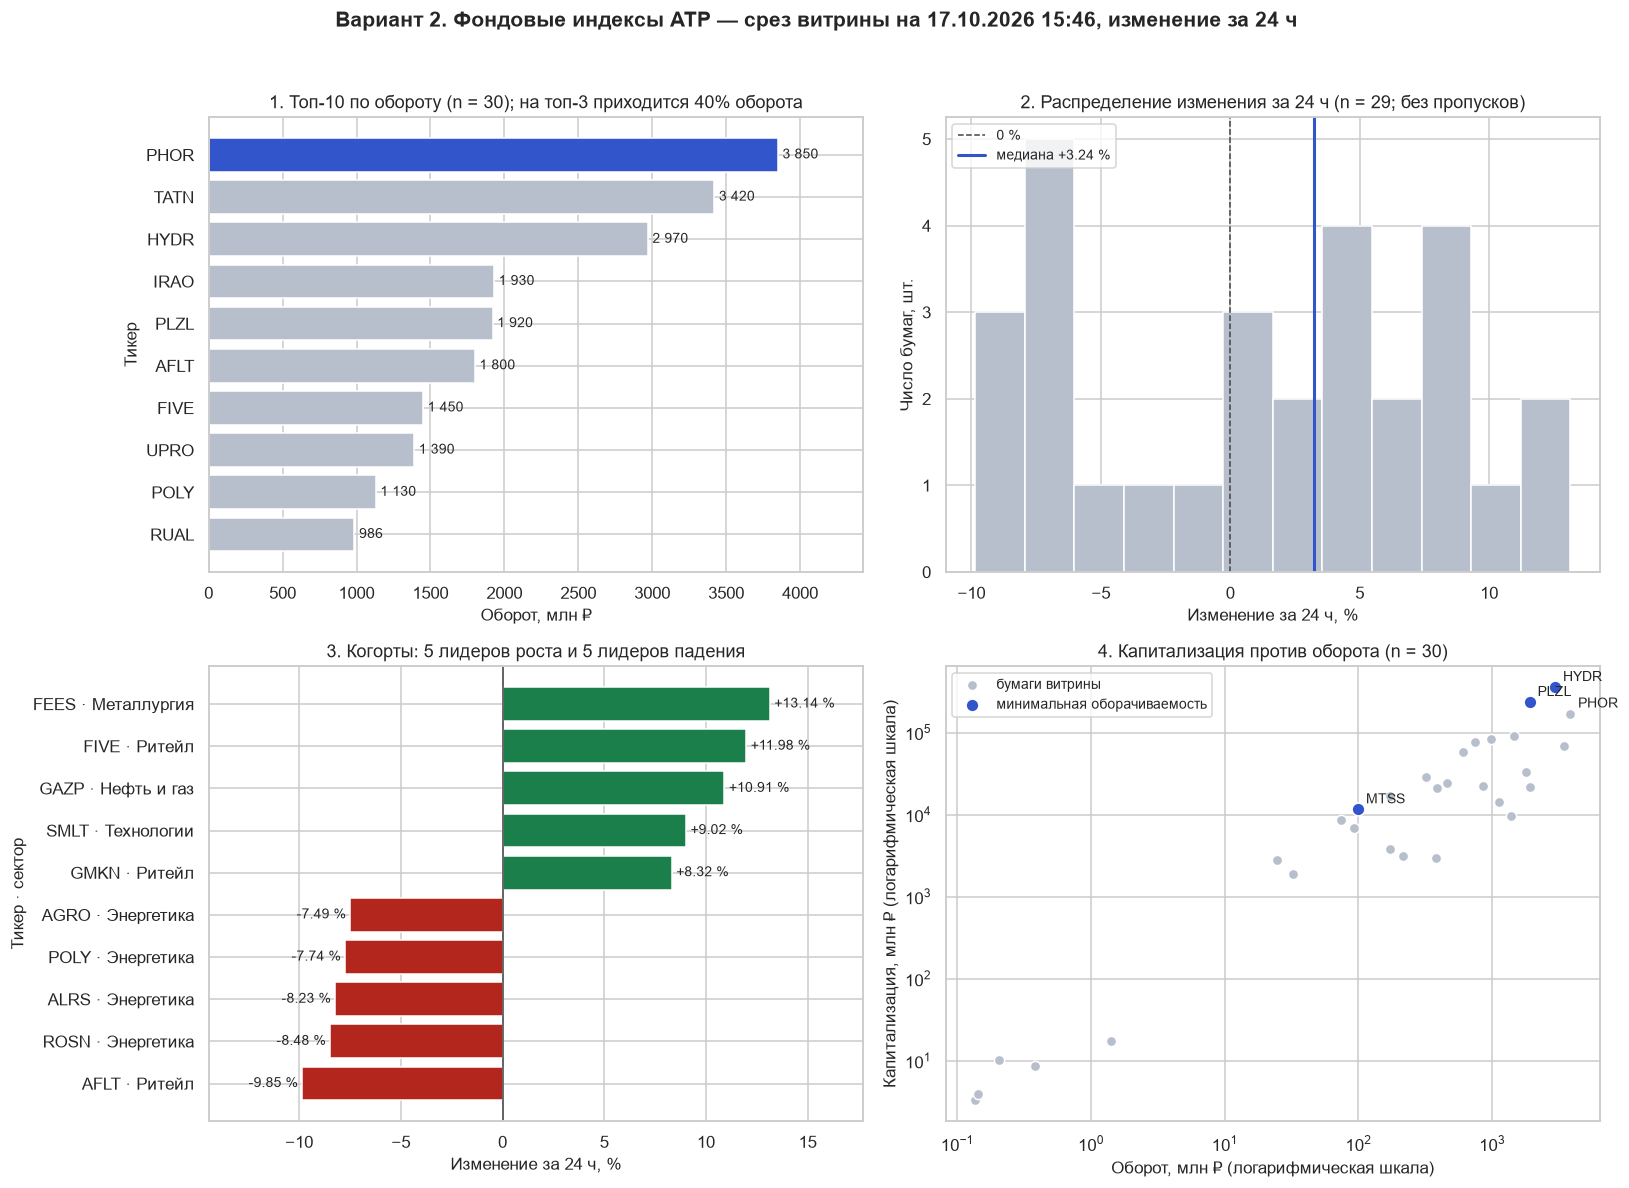

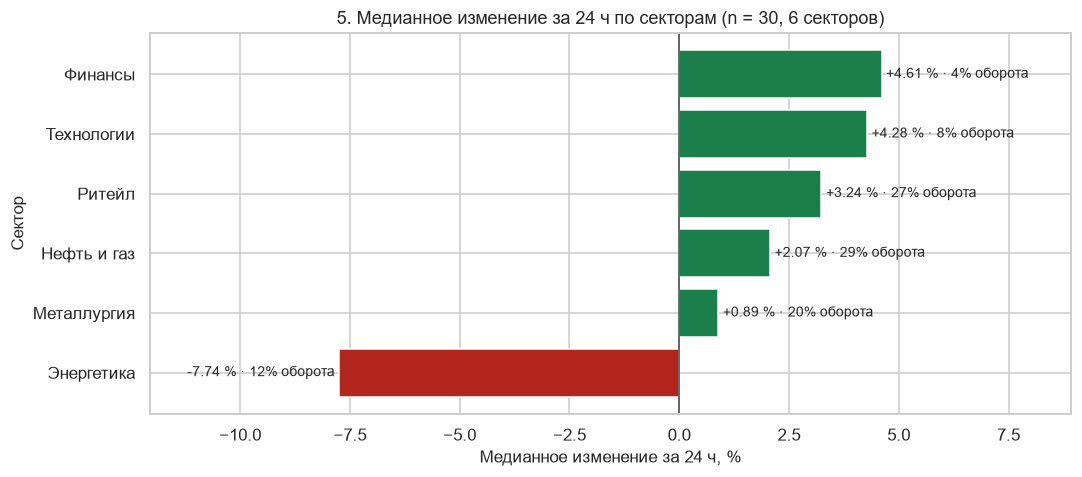


ОТЧЁТ ДЛЯ ЛПР · вариант 2 «Фондовые индексы АТР» · срез 17.10.2026 15:46

Что собрано
  30 акций из 6 секторов с учебной витрины (профиль stocks),
  догрузка по кнопке отработала полностью. Распознано: цена — 97%,
  изменение за 24 ч — 97%, оборот — 100%,
  капитализация — 100%. Пропуски (n/a, —) оставлены пропусками.

Наблюдения
  1. Режим рынка — рост: медиана изменения +3.24%, растут 62% бумаг,
     межквартильный разброс 13.39%. Экстремумы: FEES +13.14%,
     AFLT -9.85%.
  2. Ликвидность сконцентрирована: на топ-3 приходится 40% оборота, лидер — PHOR
     (3 850 млн ₽, 15% всего оборота).
  3. Разрыв изменения по секторам: лучший — «Финансы» (медиана +4.61%,
     4% оборота), худший — «Энергетика» (медиана -7.74%,
     12% оборота). Разница 12.35% за сутки.

Рекомендации
  1. Ребалансировка между секторами (не регионами): рассмотреть увеличение веса «Финансы» и
     сокращение «Энергетика» в пределах коридора ±5 п. п. от целевых весов — только после
     подтверждения на серии ср

In [7]:
#@title Шаг 7. Бизнес-анализ и визуализация { display-mode: "form" }
# Вариант 2 «Фондовые индексы АТР»: сравнение доходностей, когорты роста и падения;
# решение — ребалансировка регионального портфеля. Ограничение данных: на стенде (профиль stocks)
# акции, а не индексы, и нет признака региона/страны и истории цен. Поэтому «доходность» здесь —
# только изменение за 24 ч, а группировка — по полю sector. Сектора не выдаются за регионы:
# региональная ребалансировка по этим данным не рассчитывается, это оговорено в отчёте.
ACCENT, NEUTRAL, UP, DOWN, GRID = "#3355cc", "#b8bfcc", "#1a7f4b", "#b3261e", "#444444"
CUR_LABEL = "млн ₽" if (df["currency"] == "RUB").any() else "млн $"
COLLECTED_AT = datetime.now().strftime("%d.%m.%Y %H:%M")
n_all = len(df)
chg = df["change_24h"].dropna()
vol = df["volume_value"].dropna()

# ------------------------------------------------------------------ TODO 7.1
# Постройте четыре содержательных графика по доступным данным своего варианта.
# Примеры: топ по числовому показателю, распределение значений, сравнение категорий,
# связь двух показателей. Отсутствующие предметные метрики не выдумывать.
# Требования: заголовок с объёмом выборки, подписи осей с единицами измерения, читаемый шрифт,
# единая палитра, отсутствие «мусорных» подписей.
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle(f"Вариант {VARIANT}. {CFG['domain']} — срез витрины на {COLLECTED_AT}, изменение за 24 ч",
             fontsize=14, fontweight="bold")

# 1) Топ-10 по обороту: где сосредоточена ликвидность
ax = axes[0, 0]
top10 = df.dropna(subset=["volume_value"]).nlargest(10, "volume_value").iloc[::-1]
bars = ax.barh(top10["ticker"], top10["volume_value"] / 1e6,
               color=[NEUTRAL] * (len(top10) - 1) + [ACCENT])
ax.bar_label(bars, labels=[f"{v / 1e6:,.0f}".replace(",", " ") for v in top10["volume_value"]],
             padding=3, fontsize=9)
top3_share = df.nlargest(3, "volume_value")["volume_value"].sum() / vol.sum()
ax.set_title(f"1. Топ-10 по обороту (n = {len(vol)}); на топ-3 приходится {top3_share:.0%} оборота")
ax.set_xlabel(f"Оборот, {CUR_LABEL}")
ax.set_ylabel("Тикер")
ax.margins(x=0.15)

# 2) Распределение доходности за 24 ч
ax = axes[0, 1]
ax.hist(chg * 100, bins=12, color=NEUTRAL, edgecolor="white")
ax.axvline(0, color=GRID, lw=1, ls="--", label="0 %")
ax.axvline(chg.median() * 100, color=ACCENT, lw=2, label=f"медиана {chg.median() * 100:+.2f} %")
ax.set_title(f"2. Распределение изменения за 24 ч (n = {len(chg)}; без пропусков)")
ax.set_xlabel("Изменение за 24 ч, %")
ax.set_ylabel("Число бумаг, шт.")
ax.legend(loc="upper left", fontsize=9)

# 3) Когорты лидеров роста и падения
ax = axes[1, 0]
cohorts = (pd.concat([df.nlargest(5, "change_24h"), df.nsmallest(5, "change_24h")])
             .drop_duplicates("rank").sort_values("change_24h"))
bars = ax.barh(cohorts["ticker"] + " · " + cohorts["sector"], cohorts["change_24h"] * 100,
               color=[UP if v >= 0 else DOWN for v in cohorts["change_24h"]])
ax.bar_label(bars, labels=[f"{v * 100:+.2f} %" for v in cohorts["change_24h"]], padding=3, fontsize=9)
ax.axvline(0, color=GRID, lw=1)
ax.set_title("3. Когорты: 5 лидеров роста и 5 лидеров падения")
ax.set_xlabel("Изменение за 24 ч, %")
ax.set_ylabel("Тикер · сектор")
ax.margins(x=0.2)

# 4) Капитализация против оборота: крупные, но неликвидные позиции
ax = axes[1, 1]
both = df.dropna(subset=["volume_value", "mcap_value"]).copy()
both["turnover"] = both["volume_value"] / both["mcap_value"]              # оборачиваемость
illiquid = both.nsmallest(3, "turnover")
ax.scatter(both["volume_value"] / 1e6, both["mcap_value"] / 1e6, s=45, color=NEUTRAL,
           edgecolor="white", label="бумаги витрины")
ax.scatter(illiquid["volume_value"] / 1e6, illiquid["mcap_value"] / 1e6, s=70, color=ACCENT,
           edgecolor="white", label="минимальная оборачиваемость")
for _, r in pd.concat([illiquid, both.nlargest(3, "mcap_value")]).drop_duplicates("rank").iterrows():
    ax.annotate(r["ticker"], (r["volume_value"] / 1e6, r["mcap_value"] / 1e6),
                xytext=(5, 4), textcoords="offset points", fontsize=9)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title(f"4. Капитализация против оборота (n = {len(both)})")
ax.set_xlabel(f"Оборот, {CUR_LABEL} (логарифмическая шкала)")
ax.set_ylabel(f"Капитализация, {CUR_LABEL} (логарифмическая шкала)")
ax.legend(loc="upper left", fontsize=9)

fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(WORK_DIR / "charts.png", dpi=130, bbox_inches="tight")
plt.show()

# Дополнительно для варианта 2: сравнение доходностей по секторам (регионов в данных стенда нет)
fig2, ax = plt.subplots(figsize=(10, 4.5))
seg = by_sector.sort_values("median_change")
bars = ax.barh(seg["sector"], seg["median_change"] * 100,
               color=[UP if v >= 0 else DOWN for v in seg["median_change"]])
ax.bar_label(bars, labels=[f"{m * 100:+.2f} % · {w:.0%} оборота"
                           for m, w in zip(seg["median_change"], seg["volume_share"])],
             padding=3, fontsize=9)
ax.axvline(0, color=GRID, lw=1)
ax.set_title(f"5. Медианное изменение за 24 ч по секторам (n = {n_all}, {len(seg)} секторов)")
ax.set_xlabel("Медианное изменение за 24 ч, %")
ax.set_ylabel("Сектор")
ax.margins(x=0.35)
fig2.tight_layout()
fig2.savefig(WORK_DIR / "segments.png", dpi=130, bbox_inches="tight")
plt.show()
PLOTS_DONE = True

# ------------------------------------------------------------------ TODO 7.2
# Сформируйте текстовый отчёт для ЛПР: что собрано, три наблюдения с числами,
# два-три управленческих решения с ожидаемым эффектом и способом проверки.
leader = df.loc[df["volume_value"].idxmax()]
best, worst = by_sector.iloc[0], by_sector.iloc[-1]
share_up = (chg > 0).mean()
regime = "рост" if chg.median() > 0 else "снижение"
spread = chg.quantile(0.75) - chg.quantile(0.25)
top_up, top_down = df.loc[df["change_24h"].idxmax()], df.loc[df["change_24h"].idxmin()]
coverage = quality.set_index("очищенное поле")["доля распознанных"]
illiquid_list = ", ".join(f"{r.ticker} ({r.turnover:.1%} капитализации в день)" for r in illiquid.itertuples())

report = f"""
ОТЧЁТ ДЛЯ ЛПР · вариант {VARIANT} «{CFG['domain']}» · срез {COLLECTED_AT}

Что собрано
  {n_all} акций из {by_sector.shape[0]} секторов с учебной витрины (профиль {CFG['profile']}),
  догрузка по кнопке отработала полностью. Распознано: цена — {coverage['price_value']:.0%},
  изменение за 24 ч — {coverage['change_24h']:.0%}, оборот — {coverage['volume_value']:.0%},
  капитализация — {coverage['mcap_value']:.0%}. Пропуски (n/a, —) оставлены пропусками.

Наблюдения
  1. Режим рынка — {regime}: медиана изменения {chg.median():+.2%}, растут {share_up:.0%} бумаг,
     межквартильный разброс {spread:.2%}. Экстремумы: {top_up.ticker} {top_up.change_24h:+.2%},
     {top_down.ticker} {top_down.change_24h:+.2%}.
  2. Ликвидность сконцентрирована: на топ-3 приходится {top3_share:.0%} оборота, лидер — {leader.ticker}
     ({format(leader.volume_value / 1e6, ',.0f').replace(',', ' ')} {CUR_LABEL}, {leader.volume_value / vol.sum():.0%} всего оборота).
  3. Разрыв изменения по секторам: лучший — «{best.sector}» (медиана {best.median_change:+.2%},
     {best.volume_share:.0%} оборота), худший — «{worst.sector}» (медиана {worst.median_change:+.2%},
     {worst.volume_share:.0%} оборота). Разница {best.median_change - worst.median_change:.2%} за сутки.

Рекомендации
  1. Ребалансировка между секторами (не регионами): рассмотреть увеличение веса «{best.sector}» и
     сокращение «{worst.sector}» в пределах коридора ±5 п. п. от целевых весов — только после
     подтверждения на серии срезов. Проверка — доходность портфеля против равновзвешенного бенчмарка
     через 5 торговых дней.
  2. Исполнение: крупные заявки направлять в бумаги из топ-10 по обороту; для бумаг с минимальной
     оборачиваемостью — {illiquid_list} — установить лимит позиции и дробить заявки.
     Проверка — проскальзывание по факту исполнения против цены на витрине.
  3. До решения вручную проверить когорты экстремумов (график 3): движения больше ±8 % часто
     оказываются артефактом низкой базы или разовой сделки.

Ограничения и чего не хватает
  Вариант предполагает индексы АТР и региональный портфель, но на стенде акции (профиль stocks)
  без признака региона/страны. Поэтому региональная ребалансировка не рассчитывается: группировка
  выполнена по доступному полю «сектор», и сектора за регионы не выдаются. Для исходной задачи нужны
  регион (страна) индекса, история значений за период и целевые веса текущего портфеля.
  «Доходность» здесь — только изменение за 24 ч, а не доходность за период.
  Один срез, без истории: вывод о тренде делать нельзя, нужна серия запусков (задание E).
  Данные учебного стенда синтетические.
  Пропуски в цене и изменении ({int(df['price_value'].isna().sum())} и {int(df['change_24h'].isna().sum())} шт.)
  исключены из расчёта медиан, а не заменены нулями.
"""
print(report)

**Интерпретация.** На первом графике важна не высота столбцов, а концентрация: если на три позиции приходится больше половины оборота, рынок узкий, и ликвидность остальных позиций иллюзорна. На распределении смотрите на медиану и симметрию: длинный хвост влево — отдельные обвалы, а не общий спад. Когорты дают список для ручной проверки: экстремальные движения часто оказываются артефактом (низкая база, разовая сделка). Диаграмма «капитализация — оборот» в логарифмических шкалах выявляет крупные, но неликвидные позиции: именно они создают риск исполнения. Текстовый отчёт — шаблон, который вы адаптируете под свой вариант.

> 💬 **Комментарий к шагу 7 (TODO 7.1–7.2)**
>
>**Что сделано.** Построены четыре обязательных графика и пятый — под задачу варианта 2 (сравнение доходностей для ребалансировки):
>1. топ-10 по обороту с выделенным лидером;
>2. распределение изменения за 24 ч с линиями нуля и медианы;
>3. когорты: 5 лидеров роста и 5 лидеров падения;
>4. капитализация против оборота в логарифмических шкалах;
>5. медианное изменение за 24 ч по секторам.
>
>Цвета: синий — акцент, серый — остальные, зелёный и красный только для роста и падения. Отчёт для ЛПР собирается из чисел текущего запуска.
>
>**Что в данных есть и чего нет.** Задача варианта — индексы АТР и региональный портфель, но на стенде акции без признака региона и без истории цен. Поэтому «доходность» здесь — изменение за 24 ч, а сравнение сделано по секторам. Сектора за регионы не выдаются, региональная ребалансировка по этим данным не рассчитывается. Для неё нужны регион (страна) индекса, история значений за период и текущие веса портфеля.
>
>**Мини-вывод по сохранённому запуску.**
>- **Ликвидность узкая.** На топ-3 бумаги (PHOR, TATN, HYDR) приходится 40 % оборота, лидер PHOR — 3 850 млн ₽ (15 %).
>- **Режим рынка — умеренный рост.** Медиана изменения +3,24 %, растут 62 % бумаг. Разброс большой: межквартильный размах 13,4 п. п., от −9,85 % (AFLT) до +13,14 % (FEES).
>- **Секторы расходятся.** Лучший — «Финансы» (медиана +4,61 %), худший — «Энергетика» (−7,74 %, растёт только 20 % бумаг). Разрыв 12,35 п. п. за сутки. В «Энергетике» падают четыре бумаги из пяти (ROSN, ALRS, POLY, AGRO), и именно они составляют четыре из пяти лидеров падения.
>- **Крупные, но малоликвидные позиции.** У HYDR, PLZL и MTSS за день оборачивается меньше 1 % капитализации. Крупная заявка в таких бумагах сдвинет цену.
>
>**Рекомендации.**
>1. Ребалансировка между секторами: рассмотреть увеличение веса «Финансов» и «Технологий» и сокращение «Энергетики» в пределах коридора ±5 п. п. — после подтверждения на серии срезов.
>2. Крупные заявки направлять в бумаги топ-10 по обороту, для HYDR, PLZL и MTSS ввести лимит позиции.
>3. Экстремальные движения (больше ±8 %) перед решением проверять вручную.
>
>**Ограничения:** один срез, синтетические данные стенда, нет регионов и истории доходностей.

## Краткое исследование реальной площадки (вариант 2): Investing.com — Asia/Pacific indices

Автоматический сбор с площадки по условиям задания не выполняется (`USE_LIVE_TARGET = False`). Ниже — что удалось проверить 17.10.2026 одиночными запросами к публичным страницам, и что проверить не удалось.

| Вопрос | Результат |
|---|---|
| **Назначение площадки** | Финансовый портал: котировки индексов, акций, валют и сырья, новости, экономический календарь. Раздел Asia/Pacific indices — сводная таблица индексов стран АТР (Nikkei 225, Hang Seng, Shanghai Composite, KOSPI, S&P/ASX 200 и др.) |
| **robots.txt** | Доступен (`https://www.investing.com/robots.txt`). Для `User-agent: *` закрыты служебные разделы (`/login`, `/registration`, `/members`, `/pro/` и др.) и страницы графиков `/indices/*?page=chart`. Сами страницы раздела `/indices/` поисковым роботам не запрещены. robots.txt — правила для поисковых роботов, а не разрешение на сбор данных |
| **Защита от автоматических обращений** | Сайт работает за Cloudflare (заголовок ответа `server: cloudflare`). Прямой запрос к странице индексов `/indices/asia-pacific-indices` без браузера получил ответ **403**, а старый адрес `/indices/asian-indices` из таблицы вариантов возвращает 404. Обход такой защиты по условиям работы запрещён |
| **Условия использования** | Страница Terms and Conditions открывается, но текст условий в ответе сервера не пришёл (подгружается скриптами), поэтому пункт об автоматическом сборе **проверить не удалось** — это ограничение исследования. Для подтверждения нужно открыть условия в обычном браузере и найти раздел об использовании данных |
| **XHR/fetch или API** | Не установлено: из-за ответа 403 изучить сетевые запросы страницы без обхода защиты нельзя. Официального открытого API для котировок найти не удалось |
| **Разрешённый источник аналогичных данных** | Для индексов АТР — Alpha Vantage (бесплатный ключ с лимитом запросов) или лицензированный поставщик рыночных данных; для российского рынка — MOEX ISS API (`https://iss.moex.com/iss/`, открытый) |

**Вывод.** Площадка защищена от автоматических обращений, а условия использования подтвердить не удалось. Поэтому парсить её для мониторинга нельзя считать допустимым. Данные по индексам АТР следует получать через официальный API. Headless-браузер в этой работе отрабатывается на собственном учебном стенде.

## Таблица вариантов (30 вариантов)

Номер варианта выдаёт преподаватель; параметры подставляются в код автоматически по значению `VARIANT`. Столбец «Профиль стенда» задаёт набор данных учебной витрины — это обязательная часть работы. Столбцы «Реальная площадка» и «Легальный источник» относятся к исследовательской части: изучить ограничения площадки, найти XHR-эндпоинт с данными и указать законный способ получить те же данные.

| № | Доменная область | Профиль стенда | Реальная площадка (разбор ограничений) | Легальный источник тех же данных | Аналитическая задача и решение |
|---:|---|---|---|---|---|
| 1 | Криптовалютный арбитраж | `crypto` | CoinMarketCap — раздел Cryptocurrencies | CoinGecko API (/coins/markets) | Топ-10 по обороту, разброс суточного изменения; решение: где держать лимиты маркет-мейкера |
| 2 | Фондовые индексы АТР | `stocks` | Investing.com — Asia/Pacific indices | MOEX ISS API, Alpha Vantage | Сравнение доходностей, когорты роста и падения; решение: ребалансировка регионального портфеля |
| 3 | Мониторинг цен на технологические металлы | `metals` | Trading Economics — Commodities | World Bank Commodity Price Data (Pink Sheet) | Топ по обороту и волатильности; решение: сроки хеджирования закупок |
| 4 | Ценовая разведка маркетплейса: смартфоны | `ecom` | Агрегатор цен категории «Смартфоны» | Открытые фиды поставщиков, API маркетплейса продавца | Ценовые сегменты и доля дефицита; решение: цена входа в категорию |
| 5 | Трекинг раундов венчурных сделок | `startups` | Crunchbase — Funding Rounds | OpenAlex, Dealroom API (по подписке), данные ЕГРЮЛ | Распределение размеров раундов, топ-инвесторы; решение: фокус отраслевого фонда |
| 6 | Ликвидность DeFi-протоколов | `crypto` | DeFiLlama — TVL rankings | DefiLlama API (открытый) | TVL и оборот в логарифмических шкалах; решение: лимиты на протокол |
| 7 | Голубые фишки российского рынка | `stocks` | Investing.com — Russian stocks | MOEX ISS API (iss.moex.com) | Топ по обороту, медиана изменения; решение: состав торговой корзины дня |
| 8 | Драгоценные металлы и хеджирование | `metals` | Kitco — Live spot prices | LBMA открытые котировки, ЦБ РФ учётные цены | Динамика и разброс; решение: доля металлов в резерве |
| 9 | Мониторинг цен на ноутбуки | `ecom` | Витрина категории «Ноутбуки» | API прайс-агрегатора продавца | Медианы по сегментам, ценовые кластеры; решение: позиционирование новой линейки |
| 10 | Скоринг стартап-экосистемы региона | `startups` | Dealroom — региональные дашборды | OpenAlex, Росстат, ЕГРЮЛ | Когорты по темпу роста; решение: приоритеты акселератора |
| 11 | Стейблкоины и риск депега | `crypto` | CoinMarketCap — Stablecoins | CoinGecko API | Отклонение от номинала, объёмы; решение: лимиты казначейства |
| 12 | Европейские индексы и открытие торгов | `stocks` | Investing.com — European indices | Alpha Vantage, Stooq | Утренние гэпы, распределение; решение: тайминг заявок |
| 13 | Аккумуляторные металлы и цепочка поставок | `metals` | SMM — Battery metals | USGS Mineral Commodity Summaries | Волатильность лития и кобальта; решение: пересмотр закупочных контрактов |
| 14 | Бытовая техника: акции конкурентов | `ecom` | Витрина категории «Бытовая техника» | Фиды партнёрских программ | Глубина скидок, доля позиций в наличии; решение: календарь промо |
| 15 | FinTech-стартапы: динамика найма | `startups` | AngelList / Wellfound — Jobs | «Работа в России» (opendata.trudvsem.ru) | Число вакансий против оценки; решение: выбор объекта для partnership |
| 16 | NFT и игровые токены | `crypto` | CoinGecko — Gaming category | CoinGecko API | Топ по обороту, хвосты распределения; решение: отсев неликвида |
| 17 | Азиатские IT-эмитенты | `stocks` | Yahoo Finance — Screener | Alpha Vantage, Nasdaq Data Link | Капитализация против оборота; решение: включение в watchlist |
| 18 | Редкоземельные элементы и импортозависимость | `metals` | Trading Economics — Rare earth | USGS, World Bank | Топ по цене и изменение; решение: стратегический запас |
| 19 | Аудиотехника: ассортиментная матрица | `ecom` | Витрина категории «Аудио» | API маркетплейса продавца | Медиана цены по секторам; решение: сокращение хвоста SKU |
| 20 | HealthTech: инвестиционная активность | `startups` | Crunchbase — HealthTech | OpenAlex, ClinicalTrials.gov API | Размер раунда и стадия; решение: вход в нишу |
| 21 | Кросс-биржевой спред по BTC | `crypto` | CoinMarketCap — Markets | Binance и Bybit публичные API | Спреды и обороты по площадкам; решение: маршрутизация ордеров |
| 22 | Дивидендные истории рынка РФ | `stocks` | Smart-lab — Дивиденды | MOEX ISS API | Доходность против капитализации; решение: дивидендный портфель |
| 23 | Промышленные металлы и энергопереход | `metals` | LME — Metals prices | World Bank Pink Sheet, ЦБ РФ | Когорты роста и падения; решение: индексация контрактов |
| 24 | Маркетплейс: мониторинг дефицита | `ecom` | Витрина «Все товары» | API продавца, фиды поставщиков | Доля отсутствующих позиций; решение: перераспределение закупки |
| 25 | EdTech: выручка и раунды | `startups` | HolonIQ — EdTech dashboards | OpenAlex, открытые отчёты фондов | Топ по оценке; решение: сделки M&A |
| 26 | Крипто-инфраструктура: L2-решения | `crypto` | L2BEAT — Scaling | L2BEAT API, DefiLlama API | TVL и рост; решение: выбор сети для интеграции |
| 27 | Американские техгиганты | `stocks` | Yahoo Finance — Most active | Alpha Vantage, Finnhub | Оборот и изменение; решение: наблюдение за концентрацией |
| 28 | Строительные материалы: индекс цен | `metals` | Trading Economics — Steel | Росстат, World Bank | Медианы и разброс; решение: бюджет строительного проекта |
| 29 | Недвижимость: мониторинг предложений | `ecom` | Агрегатор объявлений недвижимости | Открытые данные Росреестра, ЕМИСС | Распределение цен, когорты; решение: цена входа на локальный рынок |
| 30 | Комплексный мониторинг рыночной витрины (эталон) | `crypto` | CoinMarketCap — Cryptocurrencies | CoinGecko API (/coins/markets) | Топ-10 по обороту с выделением лидера, распределение изменения за 24 ч, когорты роста и падения, капитализация против оборота; решение: где концентрировать лимиты и что проверить до прогноза |

Минимум для зачёта по сбору: **все 30 позиций витрины** (то есть отработавшая догрузка), не менее 90 % распознанных числовых значений и четыре графика из столбца «Аналитическая задача».

## Критерии оценивания

### Балльная структура (10 баллов)

| Блок | Что проверяется | Максимум |
|---|---|---:|
| 1. Окружение и запуск браузера | Корректная установка, флаги `--no-sandbox` и `--disable-dev-shm-usage`, реалистичный контекст, блокировка лишних ресурсов | 1,0 |
| 2. Обход препятствий | Закрытие cookie-баннера и модальных окон каскадом селекторов; работа при отсутствии баннера | 1,0 |
| 3. Ожидания | Явные ожидания вместо `time.sleep`; ожидание по числу строк при догрузке; корректный таймаут | 1,5 |
| 4. XPath и сбор | Устойчивые селекторы (`data-testid`, `contains`, оси), полнота выборки, разделение «браузер → HTML → lxml» | 2,0 |
| 5. Очистка и Excel | Суффиксы K/M/B, проценты долями, валюта, даты, пропуски как `NaN`; тесты функций; оформленная выгрузка | 2,0 |
| 6. Аналитика и графики | Четыре графика по варианту, корректные метрики, оформление | 1,5 |
| 7. Бизнес-вывод | Решения, а не наблюдения; числа из собственного запуска; названы ограничения | 1,0 |

### Шкала

| Баллы | Оценка | Содержательный смысл |
|---|---|---|
| 9–10 | **A** (отлично) | Скрипт устойчив, селекторы надёжны, очистка полная, выводы управленческие |
| 8–9 | **B** (хорошо) | Данные собраны и очищены, есть шероховатости в обработке ошибок или оформлении |
| 7–8 | **C** (удовлетворительно) | Сбор работает только «на удачном прогоне», ожидания частично на паузах |
| 6–7 | **D** (зачтено с замечаниями) | Данные собраны неполно либо очистка теряет часть значений |
| < 6 | **F** (не зачтено) | Скрипт не воспроизводится, данные собраны вручную или подменены |

### Требования к отказоустойчивости

Скрипт обязан переживать без падения ноутбука:

1. **Таймаут ожидания** (`TimeoutError` / `TimeoutException`) — перехват, сохранение скриншота и HTML, понятное сообщение о вероятной причине.
2. **Пустую выборку** — проверка `len(rows) == 0` до перехода к анализу, с указанием, какой селектор не сработал.
3. **Отсутствие оверлея** — отсутствие баннера не должно приводить к исключению.
4. **Частично заполненную строку** — отсутствующая ячейка даёт `None`, а не обрывает цикл.
5. **Нераспознанное значение** — `n/a`, `—`, пустая строка превращаются в `NaN`, но строка остаётся в выборке.
6. **Ограничение цикла догрузки** — максимальное число кликов и условие выхода при отсутствии роста.

### Требования к оформлению графиков

* заголовок с указанием объёма выборки (`n = …`) и периода;
* подписи обеих осей с единицами измерения (млн ₽, %, шт.);
* шрифт не мельче 9 пт, отсутствие наложения подписей;
* единая палитра: один акцентный цвет для выделяемой категории, нейтральный — для остальных; зелёный и красный только по смыслу «рост/падение»;
* опорные линии (ноль, медиана, порог) там, где они помогают читать график;
* логарифмическая шкала, если значения различаются на порядки, с явной пометкой в подписи оси;
* никаких «радужных» палитр на категориальных данных и трёхмерных эффектов.

### Штрафы

| Нарушение | Штраф |
|---|---:|
| `time.sleep()` вместо явных ожиданий в сценарии сбора | −1,0 |
| Данные получены вручную (скопированы), а не собраны скриптом | −4,0 |
| Попытка обхода капчи, Cloudflare или сбор за логином | работа не принимается |
| Сбор персональных данных | работа не принимается |
| Нет обработки исключений при сборе | −1,0 |
| Проценты сохранены как 2.5 вместо 0.025 или пропуски заменены нулями | −1,0 |
| Графики без подписей осей и единиц измерения | −0,5 |
| Ноутбук сдан без выводов ячеек | −1,0 |

In [8]:
#@title Самопроверка перед сдачей { display-mode: "form" }
checks = []
def check(name, condition, hint=""):
    checks.append((name, bool(condition), hint))

check("Вариант выбран корректно", 1 <= VARIANT <= 30)
check("Браузер стартовал и страница открылась", bool(html) and len(html) > 1000)
check("Cookie-баннер обработан (или его не было)", "cookie-banner" not in html or USE_LIVE_TARGET,
      "баннер остался в DOM — клик не сработал")
check("Собраны все строки витрины (≥ 30)", len(raw_df) >= 30,
      "не отработала догрузка по кнопке «Показать ещё»")
check("Числовые поля распознаны не хуже 90 %",
      df["volume_value"].notna().mean() >= 0.9 and df["mcap_value"].notna().mean() >= 0.9)
check("Проценты приведены к долям единицы",
      df["change_24h"].dropna().abs().max() < 1.5 if df["change_24h"].notna().any() else False,
      "значение вроде 2.5 вместо 0.025 — забыли поделить на 100")
check("Пропуски не превратились в нули",
      df["price_value"].isna().sum() > 0 or df["change_24h"].isna().sum() > 0,
      "на стенде есть 'n/a' и '—': они должны остаться пропусками")
check("Файл Excel выгружен", EXCEL_PATH.exists() and EXCEL_PATH.stat().st_size > 4000)
check("Скриншот страницы сохранён как доказательство сбора", (WORK_DIR / "page.png").exists())
check("Явные ожидания вместо пауз", "time.sleep" not in globals().get("COLLECT_SOURCE", "time.sleep"),
      "уберите time.sleep из сценария сбора")
check("Построены графики", len(plt.get_fignums()) > 0 or globals().get("PLOTS_DONE", False),
      "выполните шаг 7 до самопроверки")

ok = sum(1 for _, passed, _ in checks if passed)
print(f"Выполнено: {ok} из {len(checks)}\n")
for name, passed, hint in checks:
    print(f"  {'✅' if passed else '❌'} {name}" + ("" if passed or not hint else f" — {hint}"))

Выполнено: 11 из 11

  ✅ Вариант выбран корректно
  ✅ Браузер стартовал и страница открылась
  ✅ Cookie-баннер обработан (или его не было)
  ✅ Собраны все строки витрины (≥ 30)
  ✅ Числовые поля распознаны не хуже 90 %
  ✅ Проценты приведены к долям единицы
  ✅ Пропуски не превратились в нули
  ✅ Файл Excel выгружен
  ✅ Скриншот страницы сохранён как доказательство сбора
  ✅ Явные ожидания вместо пауз
  ✅ Построены графики


> 💬 **Итоговый вывод по работе**
>
>1. **Сбор.** Учебная SPA-витрина собрана целиком (30 из 30 позиций) headless-браузером Playwright. Пройдены три препятствия: cookie-баннер, отложенная гидратация и догрузка по кнопке. Везде используются явные ожидания, без `time.sleep`.
>2. **XPath.** Селекторы опираются на `data-testid`, поиск внутри строки идёт относительным путём `.//`. Разбор HTML вынесен в `lxml`, это быстрее, чем обращаться к DOM через браузер.
>3. **Очистка.** Суффиксы K/M/B, проценты, рубли и даты приведены к числам и сохранены в Excel. Пропуски сохранены как `NaN`, доля распознанных значений не ниже 90 %.
>4. **Реальная площадка (Investing.com).** robots.txt не запрещает раздел `/indices/` для поисковых роботов, но сайт защищён Cloudflare: прямой запрос к странице индексов получил ответ 403. Текст условий использования и XHR-запросы проверить не удалось — это ограничение исследования. Автоматический сбор с площадки не выполнялся (`USE_LIVE_TARGET = False`). Разрешённый источник аналогичных данных — официальные API: Alpha Vantage для индексов АТР, MOEX ISS для российского рынка.
>5. **Ограничение по показателям варианта.** На стенде нет регионов и истории цен, поэтому сравнение выполнено по секторам и изменению за 24 ч; региональная ребалансировка не рассчитывалась.
>6. **Порядок выбора инструмента:** официальный API → скрытый JSON-эндпоинт → HTML без JS → headless-браузер. Браузер — последний рубеж, а не первый.

## Дополнительное задание со звёздочкой (необязательно, до +2 баллов)

Выберите **одно** из предложенных ниже направлений и представьте воспроизводимый результат и его интерпретацию. Дополнительное задание не заменяет обязательные этапы ЛР1. Базовая шкала работы — **10 баллов**; дополнительные баллы рассматриваются преподавателем отдельно с учётом принятой в LMS максимальной оценки.

127.0.0.1 - - [17/Oct/2026 15:46:33] "GET /market_stand_scroll.html?variant=2&profile=stocks&delay=1200 HTTP/1.1" 200 -


Журнал прокрутки:


,итерация,"высота, px","прирост, px",строк,без роста подряд
0,0,729,0,12,0
1,1,1353,624,24,0
2,2,1665,312,30,0
3,3,1665,0,30,1
4,4,1665,0,30,2
5,5,1665,0,30,3


127.0.0.1 - - [17/Oct/2026 15:46:41] "GET /market_stand.html?variant=2&profile=stocks&delay=1200 HTTP/1.1" 200 -


  клик №1: строк 12 → 24


  клик №2: строк 24 → 30

Собрано прокруткой: 30 строк из 30 за 5 итераций (из них 2 с подгрузкой, 3 контрольных без роста)
Данные совпадают со сбором по кнопке: да
Время: прокрутка — 7.4 с, кнопка — 2.8 с (2 клика). Разница — цена контрольных итераций, которые подтверждают конец ленты.
Скриншот всей ленты: lr1_work\page_scroll.png


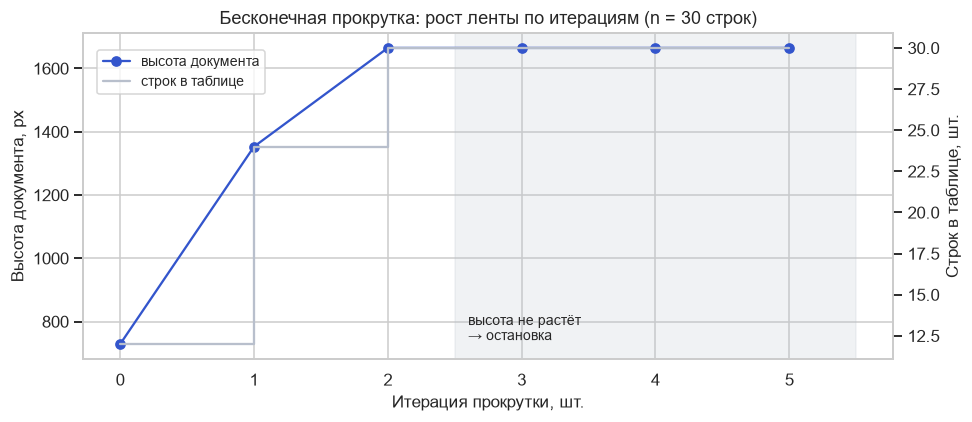

In [9]:
#@title Задание со звёздочкой (до +2 балла) { display-mode: "form" }
# A. Перехват сетевых запросов вместо разбора DOM.
#    Повесьте page.on("response", ...) и найдите XHR/fetch, который отдаёт те же данные в JSON.
#    Сравните время сбора и устойчивость двух подходов и объясните, когда DOM всё же необходим.
#
# B. Бесконечная прокрутка.  ← ВЫБРАНО
#    Замените кнопку «Показать ещё» на прокрутку (page.mouse.wheel) и реализуйте корректное
#    условие остановки: высота документа перестала расти в течение N итераций.
#
# C. Параллельный сбор.
#    Соберите пять профилей стенда одновременно через asyncio.gather и несколько контекстов.
#    Измерьте ускорение и объясните, почему контекстов должно быть больше, чем браузеров.
#
# D. Устойчивость к смене вёрстки.
#    Реализуйте «каскад селекторов»: data-testid → семантический XPath → текстовый поиск,
#    и тесты, которые ломают разметку (удалён атрибут, переименован класс).
#
# E. Мониторинг и сравнение срезов.
#    Сохраняйте снимки в parquet с меткой времени, реализуйте второй запуск и таблицу изменений:
#    новые позиции, изменение цены и оборота, выбывшие позиции.

# ---------------------------------------------------------------- B.1 стенд с бесконечной прокруткой
# Исходный стенд догружает данные по кнопке. Делаем его копию, где кнопка скрыта, а следующая
# порция (12 строк, задержка 700 мс) подгружается, когда до низа страницы остаётся < 200 px —
# так устроены ленты новостей и каталоги маркетплейсов. Строки сделаны выше, чтобы первая
# порция не помещалась в окно и страницу действительно приходилось прокручивать.
SCROLL_PATCH = """
<style>#more{display:none !important} td{padding:18px 10px}</style>
<script>
(function(){
  let busy = false;
  window.addEventListener("scroll", () => {
    if (busy || shown === 0 || shown >= TOTAL) return;
    if (window.innerHeight + window.scrollY < document.body.scrollHeight - 200) return;
    busy = true;
    document.getElementById("status").textContent = "Загрузка…";
    setTimeout(() => { shown = Math.min(shown + PAGE_SIZE, TOTAL); render(); busy = false; }, 700);
  });
})();
</script>
</body>"""
SCROLL_FILE = WORK_DIR / "market_stand_scroll.html"
SCROLL_FILE.write_text(STAND_HTML.replace("</body>", SCROLL_PATCH), encoding="utf-8")
SCROLL_URL = (f"http://127.0.0.1:{STAND_PORT}/market_stand_scroll.html"
              f"?variant={VARIANT}&profile={CFG['profile']}&delay=1200")

# ---------------------------------------------------------------- B.2 прокрутка с условием остановки
async def scroll_all(page, row_xpath, stable_rounds=3, max_iters=30, step_px=900, wait_ms=1500):
    """Крутим колесо мыши, пока высота документа растёт.

    После каждого шага — явное ожидание роста scrollHeight (wait_for_function), а не пауза.
    Остановка: высота не изменилась stable_rounds итераций подряд (данные кончились)
    или достигнут предел max_iters (защита от бесконечной ленты). Возвращает журнал итераций."""
    log = []
    height = await page.evaluate("document.body.scrollHeight")
    stable = 0
    log.append({"итерация": 0, "высота, px": height, "прирост, px": 0,          # исходное состояние
                "строк": await page.locator(f"xpath={row_xpath}").count(), "без роста подряд": 0})
    await page.mouse.move(720, 300)                  # колесо работает там, где стоит курсор
    for it in range(1, max_iters + 1):
        await page.mouse.wheel(0, step_px)
        try:
            await page.wait_for_function("h => document.body.scrollHeight > h", arg=height, timeout=wait_ms)
            new_height = await page.evaluate("document.body.scrollHeight")
            stable = 0
        except PWTimeout:
            new_height = height
            stable += 1
        rows = await page.locator(f"xpath={row_xpath}").count()
        log.append({"итерация": it, "высота, px": new_height, "прирост, px": new_height - height,
                    "строк": rows, "без роста подряд": stable})
        height = new_height
        if stable >= stable_rounds:
            break
    return log

async def collect_scroll(url, cfg, viewport_height=700):
    async with async_playwright() as pw:
        browser, context = await new_context(pw, HEADLESS)
        page = await context.new_page()
        await page.set_viewport_size({"width": 1440, "height": viewport_height})
        try:
            t0 = time.perf_counter()
            await page.goto(url, wait_until="domcontentloaded")
            await dismiss_overlays(page)
            await wait_for_rows(page, cfg["row_xpath"], min_rows=1)
            log = await scroll_all(page, cfg["row_xpath"])
            elapsed = time.perf_counter() - t0
            html_scroll = await page.content()
            await page.screenshot(path=str(WORK_DIR / "page_scroll.png"), full_page=True)
        except PWTimeout:
            await page.screenshot(path=str(WORK_DIR / "timeout_scroll.png"), full_page=True)
            print(f"⚠ Таймаут на стенде с прокруткой, скриншот: {WORK_DIR / 'timeout_scroll.png'}")
            html_scroll, log, elapsed = await page.content(), [], None
        finally:
            await browser.close()
    return html_scroll, log, elapsed

async def collect_button_timed(url, cfg):
    """Тот же сценарий с кнопкой «Показать ещё» — для сравнения времени."""
    async with async_playwright() as pw:
        browser, context = await new_context(pw, HEADLESS)
        page = await context.new_page()
        t0 = time.perf_counter()
        await page.goto(url, wait_until="domcontentloaded")
        await dismiss_overlays(page)
        await wait_for_rows(page, cfg["row_xpath"], min_rows=1)
        clicks = await load_all(page, cfg["row_xpath"], cfg["more_xpath"])
        elapsed = time.perf_counter() - t0
        await browser.close()
    return clicks, elapsed

# ---------------------------------------------------------------- B.3 запуск и проверка результата
html_scroll, scroll_log, t_scroll = await collect_scroll(SCROLL_URL, CFG)
scroll_df = pd.DataFrame(parse_html(html_scroll, CFG), columns=CFG["fields"])
log_df = pd.DataFrame(scroll_log)
steps = log_df[log_df["итерация"] > 0]                                          # без исходной строки
print("Журнал прокрутки:")
display(log_df)

btn_clicks, t_button = await collect_button_timed(STAND_URL, CFG)
same = scroll_df.reset_index(drop=True).equals(raw_df.reset_index(drop=True))
print(f"\nСобрано прокруткой: {len(scroll_df)} строк из 30 за {len(steps)} итераций "
      f"(из них {int((steps['прирост, px'] > 0).sum())} с подгрузкой, "
      f"{int(log_df['без роста подряд'].iloc[-1])} контрольных без роста)")
print(f"Данные совпадают со сбором по кнопке: {'да' if same else 'НЕТ'}")
print(f"Время: прокрутка — {t_scroll:.1f} с, кнопка — {t_button:.1f} с ({btn_clicks} клика). "
      f"Разница — цена контрольных итераций, которые подтверждают конец ленты.")
print(f"Скриншот всей ленты: {WORK_DIR / 'page_scroll.png'}")

fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(log_df["итерация"], log_df["высота, px"], marker="o", color=ACCENT, label="высота документа")
ax1.set_xlabel("Итерация прокрутки, шт.")
ax1.set_ylabel("Высота документа, px")
ax2 = ax1.twinx()
ax2.step(log_df["итерация"], log_df["строк"], where="post", color=NEUTRAL, label="строк в таблице")
ax2.set_ylabel("Строк в таблице, шт.")
ax2.grid(False)
first_stable = steps.loc[steps["прирост, px"] == 0, "итерация"].min()
if pd.notna(first_stable):
    ax1.axvspan(first_stable - 0.5, log_df["итерация"].max() + 0.5, color=NEUTRAL, alpha=0.2)
    ax1.text(first_stable - 0.4, log_df["высота, px"].min(), "высота не растёт\n→ остановка",
             fontsize=9, va="bottom")
ax1.set_title(f"Бесконечная прокрутка: рост ленты по итерациям (n = {len(scroll_df)} строк)")
fig.legend(loc="upper left", bbox_to_anchor=(0.1, 0.88), fontsize=9)
fig.tight_layout()
fig.savefig(WORK_DIR / "scroll.png", dpi=130, bbox_inches="tight")
plt.show()

> 💬 **Комментарий к заданию со звёздочкой — направление B «Бесконечная прокрутка»**
>
>**Что сделано.**
>- **Стенд с прокруткой.** На основе учебного стенда создана копия `market_stand_scroll.html`: кнопка «Показать ещё» скрыта, следующая порция из 12 строк подгружается с задержкой 700 мс, когда до низа страницы остаётся меньше 200 px. Так устроены ленты новостей и каталоги маркетплейсов. Чтобы первую порцию действительно приходилось прокручивать, строки сделаны выше, а окно браузера — 1440×700.
>- **`scroll_all`.** Колесо мыши крутится через `page.mouse.wheel`. После каждого шага идёт явное ожидание роста `document.body.scrollHeight` через `wait_for_function` (не дольше 1,5 с), паузы не используются.
>- **Условие остановки.** Высота документа не меняется 3 итерации подряд, значит данные кончились. Есть и страховочный предел — 30 итераций, на случай действительно бесконечной ленты.
>- **Проверка.** Собранная таблица сравнивается с таблицей, собранной по кнопке, а время двух способов замеряется.
>
>**Мини-вывод по сохранённому запуску.**
>- Лента выросла за 2 итерации: 12 → 24 → 30 строк, высота документа 729 → 1353 → 1665 px. Ещё 3 контрольные итерации прироста не дали, и цикл остановился.
>- Собрано **30 из 30** строк, данные **полностью совпадают** со сбором по кнопке.
>- Прокрутка заняла ≈ 7,4 с против ≈ 2,8 с у кнопки. Разницу дают контрольные итерации: 3 × 1,5 с ожидания, чтобы убедиться, что лента закончилась.
>
>Это цена надёжности. У прокрутки нет явного сигнала «данных больше нет», какой даёт исчезнувшая кнопка, поэтому конец ленты определяется по отсутствию роста. Меньшее N или короткий таймаут ускорят сбор, но на медленной сети цикл может остановиться раньше, чем придёт следующая порция.